# 07 — ML Hyperparameter Tuning

This notebook tunes Random Forest and XGBoost once for each feature set using all five predefined Validation missingness conditions. Each candidate is fitted once on the unchanged Train period, evaluated under three nested random-point conditions and two block-gap conditions, and selected using a family-balanced Validation objective that gives 50% total weight to the random family and 50% to the block family.

The Test split is never used for hyperparameter selection. The selected configuration is frozen for the separate final-evaluation notebook.

Set `TUNING_PROFILE = "pilot"` for a three-candidate smoke test. After the pilot and the weighted XGBoost audit succeed, change it to `"full"` and rerun for the final 30-candidate search.


In [1]:
# Core utilities
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from time import perf_counter
import gc
import hashlib
import json
import os
import platform
import random
import re
import sys

# Data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine-learning utilities
import sklearn
from joblib import effective_n_jobs
from packaging.version import Version
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)
from sklearn.model_selection import ParameterSampler

try:
    import xgboost
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    xgboost = None
    XGBRegressor = None
    XGBOOST_AVAILABLE = False

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


## Step 1 : Configuration

The shared protocol uses new checkpoint and artifact names, so the earlier `random30_point` tuning outputs remain untouched as a historical reference. Tuning uses all available CPU workers for feasibility. Final single-thread fitting and repeated inference remain in `07_machine_learning_imputation_final_evaluation.ipynb`.


In [2]:
SEED = 42

# Run the new protocol as a pilot first. After the pilot succeeds,
# change this to "full" and restart/run all.
TUNING_PROFILE = "full"
TUNING_ITERATIONS = {
    "pilot": 3,
    "full": 30,
}

if TUNING_PROFILE not in TUNING_ITERATIONS:
    raise ValueError(
        "TUNING_PROFILE must be either 'pilot' or 'full'."
    )

N_TUNING_ITER = TUNING_ITERATIONS[TUNING_PROFILE]

TUNING_PROTOCOL = "shared_family_balanced"
TUNING_PROTOCOL_VERSION = "shared_family_balanced_v1"
TUNING_METRIC = "FamilyBalancedValidationMAE"

# This scenario is used only for reusable feature-pipeline checks and
# the common Train matrix. It is not the sole tuning scenario.
REFERENCE_SCENARIO = "random30_point"

# New names protect the earlier random30-only tuning artifacts.
ARTIFACT_TAG = "shared_family_balanced"
PROFILE_SUFFIX = "_pilot" if TUNING_PROFILE == "pilot" else ""
OUTPUT_SUFFIX = f"_{ARTIFACT_TAG}{PROFILE_SUFFIX}"

# Parallel tuning uses all available workers.
TUNING_N_JOBS = -1

XGB_MAX_ROUNDS = 5000
XGB_EARLY_STOPPING_ROUNDS = 50
EXPECTED_XGBOOST_VERSION = "3.2.0"
XGB_WEIGHT_AUDIT_ATOL = 5e-5
XGB_WEIGHT_AUDIT_RTOL = 1e-6

# Increment this only when feature engineering or matrix construction changes.
ML_PIPELINE_VERSION = "ml_features_v2_2026-07-19"

random.seed(SEED)
np.random.seed(SEED)

TIME_COL = "Datetime"
STATION_COL = "Station"
SPLIT_COL = "Split"
SCENARIO_COL = "MaskingScenario"
TARGET_COL = "PM25_original"
MODEL_INPUT_COL = "PM25_model_input"
TEMPERATURE_COL = "Temperature"
FLAG_COLUMN = "is_artificial_masked"

SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent",
]

SCENARIO_FAMILIES = {
    "random_point": [
        "random10_point",
        "random30_point",
        "random50_point",
    ],
    "block_gap": [
        "block24_10percent",
        "block72_10percent",
    ],
}

FAMILY_WEIGHTS = {
    "random_point": 0.5,
    "block_gap": 0.5,
}

if not np.isclose(sum(FAMILY_WEIGHTS.values()), 1.0):
    raise ValueError("Family weights must sum to one.")

scenario_family_members = [
    scenario
    for family_scenarios in SCENARIO_FAMILIES.values()
    for scenario in family_scenarios
]

if sorted(scenario_family_members) != sorted(SCENARIOS):
    raise ValueError(
        "Each tuning scenario must appear exactly once in SCENARIO_FAMILIES."
    )

if len(scenario_family_members) != len(set(scenario_family_members)):
    raise ValueError("A tuning scenario appears in more than one family.")

SCENARIO_TO_FAMILY = {
    scenario: family
    for family, family_scenarios in SCENARIO_FAMILIES.items()
    for scenario in family_scenarios
}

SELECTION_SORT_COLUMNS = [
    "FamilyBalancedValidationMAE",
    "FamilyBalancedValidationRMSE",
    "FitSeconds",
    "CandidateNumber",
]

FEATURE_SETS = [
    "temporal_only",
    "spatio_temporal",
]

TRAIN_LABEL = "Train"
VALIDATION_LABEL = "Validation"
TEST_LABEL = "Test"

SUPPORTED_INPUT_SUFFIXES = {
    ".csv",
    ".parquet",
    ".pkl",
    ".pickle",
    ".feather",
}

NOTEBOOK_DIR = Path.cwd().resolve()


def find_codes_dir(start_path):
    """Locate the main Codes folder."""

    for path in [start_path, *start_path.parents]:
        if path.name.lower() == "codes":
            return path

    raise FileNotFoundError(
        f"Could not locate the Codes folder from: {start_path}"
    )


def find_table(folder, stem):
    """Find one supported table by filename stem."""

    matches = [
        path
        for path in folder.iterdir()
        if path.is_file()
        and path.stem.lower() == stem.lower()
        and path.suffix.lower() in SUPPORTED_INPUT_SUFFIXES
    ]

    if not matches:
        raise FileNotFoundError(
            f"Required file not found: {folder / stem}"
        )

    if len(matches) > 1:
        raise ValueError(
            f"Multiple files found for '{stem}': {matches}"
        )

    return matches[0]


if not XGBOOST_AVAILABLE:
    raise ImportError(
        "Notebook 07 requires xgboost. Install it, restart the "
        "kernel, and run the notebook again."
    )

if Version(xgboost.__version__) != Version(EXPECTED_XGBOOST_VERSION):
    raise RuntimeError(
        "This shared weighted-validation protocol was prepared and must "
        f"be audited with xgboost {EXPECTED_XGBOOST_VERSION}; found "
        f"{xgboost.__version__}. Install the expected version, restart "
        "the kernel, and run again."
    )

CODES_DIR = find_codes_dir(NOTEBOOK_DIR)

DATA_DIR = CODES_DIR / "data" / "modelling"
PROCESSED_DIR = CODES_DIR / "data" / "processed"
RESULTS_DIR = CODES_DIR / "results"
MODELS_DIR = CODES_DIR / "models"

OUTPUT_DIR = RESULTS_DIR / "machine_learning"
MODEL_DIR = MODELS_DIR / "machine_learning"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

DIAGNOSTIC_DIR = OUTPUT_DIR / "diagnostics"
FIGURE_DIR = OUTPUT_DIR / "figures"

for required_dir in [
    DATA_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    MODELS_DIR,
]:
    if not required_dir.exists():
        raise FileNotFoundError(
            f"Required project folder not found: {required_dir}"
        )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
DIAGNOSTIC_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

BASE_DATA_PATH = find_table(
    DATA_DIR,
    "base_modelling_dataset_before_masking",
)

SCENARIO_PATHS = {
    scenario: find_table(
        DATA_DIR,
        f"modelling_dataset_{scenario}_masked",
    )
    for scenario in SCENARIOS
}

STATION_METADATA_PATH = find_table(
    PROCESSED_DIR,
    "selected_station_metadata",
)
NEAREST_NEIGHBOURS_PATH = find_table(
    PROCESSED_DIR,
    "top3_nearest_neighbours",
)
IDW_WEIGHTS_PATH = find_table(
    PROCESSED_DIR,
    "top3_idw_weights",
)

INPUT_FILES = [
    BASE_DATA_PATH,
    *SCENARIO_PATHS.values(),
    STATION_METADATA_PATH,
    NEAREST_NEIGHBOURS_PATH,
    IDW_WEIGHTS_PATH,
]

print(f"Tuning profile: {TUNING_PROFILE}")
print(f"Tuning protocol: {TUNING_PROTOCOL_VERSION}")
print(f"Selection metric: {TUNING_METRIC}")
print(f"Tuning candidates per feature set: {N_TUNING_ITER}")
print(f"Validation scenarios: {SCENARIOS}")
print(f"Family weights: {FAMILY_WEIGHTS}")
print(f"Reference scenario for feature checks: {REFERENCE_SCENARIO}")
print(f"Codes directory: {CODES_DIR}")
print(f"Results directory: {OUTPUT_DIR}")
print(f"Models directory: {MODEL_DIR}")
print(
    "Configured tuning workers:",
    effective_n_jobs(TUNING_N_JOBS),
)
print(f"XGBoost version: {xgboost.__version__}")
print(f"Output suffix: {OUTPUT_SUFFIX}")
print("Required files:")

for file_path in INPUT_FILES:
    print(f"  {file_path.name}")


Tuning profile: full
Tuning protocol: shared_family_balanced_v1
Selection metric: FamilyBalancedValidationMAE
Tuning candidates per feature set: 30
Validation scenarios: ['random10_point', 'random30_point', 'random50_point', 'block24_10percent', 'block72_10percent']
Family weights: {'random_point': 0.5, 'block_gap': 0.5}
Reference scenario for feature checks: random30_point
Codes directory: C:\Users\Msi\Desktop\DISSERTATION\Codes
Results directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning
Models directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\machine_learning
Configured tuning workers: 12
XGBoost version: 3.2.0
Output suffix: _shared_family_balanced
Required files:
  base_modelling_dataset_before_masking.csv
  modelling_dataset_random10_point_masked.csv
  modelling_dataset_random30_point_masked.csv
  modelling_dataset_random50_point_masked.csv
  modelling_dataset_block24_10percent_masked.csv
  modelling_dataset_block72_10percent_masked.csv
  selected_s

## Step 2 : Input Checks

Required columns and split labels are checked immediately after each dataset is loaded.


In [3]:
def validate_input_labels(df, expected_scenario=None):
    """Check required columns and experiment labels."""

    required_columns = {
        TIME_COL,
        STATION_COL,
        SPLIT_COL,
        TARGET_COL,
        MODEL_INPUT_COL,
        TEMPERATURE_COL,
    }
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    observed_splits = set(df[SPLIT_COL].dropna().astype(str).unique())
    expected_splits = {TRAIN_LABEL, VALIDATION_LABEL, TEST_LABEL}

    if observed_splits != expected_splits:
        missing = expected_splits - observed_splits
        unexpected = observed_splits - expected_splits
        raise ValueError(
            f"Split mismatch. Missing: {sorted(missing)}; "
            f"Unexpected: {sorted(unexpected)}"
        )

    if expected_scenario is not None:
        if SCENARIO_COL not in df.columns:
            raise ValueError(
                f"Missing scenario column: {SCENARIO_COL}"
            )

        observed_scenarios = set(
            df[SCENARIO_COL].dropna().astype(str).unique()
        )

        if observed_scenarios != {expected_scenario}:
            raise ValueError(
                f"Scenario mismatch for {expected_scenario}: "
                f"{sorted(observed_scenarios)}"
            )


def validate_feature_columns(feature_columns):
    """Prevent direct target or current model-input leakage."""

    forbidden = {TARGET_COL, MODEL_INPUT_COL}
    leaked_columns = forbidden.intersection(feature_columns)

    if leaked_columns:
        raise ValueError(
            f"Forbidden feature columns detected: {sorted(leaked_columns)}"
        )


## Step 3 : Load and Validate Input

A reference scenario is loaded for reusable feature-engineering checks and the common Train matrix. All five Validation scenarios are audited and later enter candidate selection. The reference scenario does not receive special weight in the shared objective.


In [4]:
def read_table(path):
    """Read a supported table."""

    suffix = path.suffix.lower()

    if suffix == ".csv":
        df = pd.read_csv(path)
    elif suffix == ".parquet":
        df = pd.read_parquet(path)
    elif suffix in {".pkl", ".pickle"}:
        df = pd.read_pickle(path)
    elif suffix == ".feather":
        df = pd.read_feather(path)
    else:
        raise ValueError(
            f"Unsupported input format: {path}"
        )

    if TIME_COL in df.columns:
        df[TIME_COL] = pd.to_datetime(
            df[TIME_COL]
        )

    return df


def load_scenario(scenario):
    """Load and validate one masking scenario."""

    if scenario not in SCENARIO_PATHS:
        raise KeyError(f"Unknown scenario: {scenario}")

    df = read_table(SCENARIO_PATHS[scenario])
    validate_input_labels(
        df,
        expected_scenario=scenario,
    )
    return df


reference_df = load_scenario(
    REFERENCE_SCENARIO
)

print(
    f"Loaded reference file: "
    f"{SCENARIO_PATHS[REFERENCE_SCENARIO].name}"
)
print(f"Reference scenario: {REFERENCE_SCENARIO}")
print(f"Reference shape: {reference_df.shape}")
print(f"Stations: {reference_df[STATION_COL].nunique()}")
print(
    "All five scenario files will be used for "
    "shared Validation selection."
)
print(f"Results will be saved to: {OUTPUT_DIR}")
print(f"Models will be saved to: {MODEL_DIR}")


Loaded reference file: modelling_dataset_random30_point_masked.csv
Reference scenario: random30_point
Reference shape: (219120, 21)
Stations: 5
All five scenario files will be used for shared Validation selection.
Results will be saved to: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning
Models will be saved to: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\machine_learning


## Step 3.1 : Full Scenario Audit

All masking datasets are checked against the common base panel before feature engineering.


In [5]:
def to_boolean(series):
    """Convert a stored flag column to Boolean values."""

    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)

    converted = (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )

    if converted.isna().any():
        raise ValueError(f"Invalid Boolean values in column: {series.name}")

    return converted


base_df = read_table(BASE_DATA_PATH)
validate_input_labels(base_df)

KEY_COLUMNS = [STATION_COL, TIME_COL]
if FLAG_COLUMN not in base_df.columns:
    raise ValueError(f"Missing flag column: {FLAG_COLUMN}")

if base_df.duplicated(KEY_COLUMNS).any():
    raise ValueError("Duplicate Station-Datetime rows in base data.")

base_artificial = to_boolean(base_df[FLAG_COLUMN])

if base_artificial.any():
    raise ValueError("Artificial masks should not exist in the base dataset.")

base_sorted = (
    base_df
    .sort_values(KEY_COLUMNS)
    .reset_index(drop=True)
)

base_split_counts = (
    base_sorted[SPLIT_COL]
    .value_counts()
    .sort_index()
)

base_station_counts = (
    base_sorted[STATION_COL]
    .value_counts()
    .sort_index()
)

scenario_audit_records = []
mask_audit_records = []

for scenario in SCENARIOS:
    df = load_scenario(scenario)

    if FLAG_COLUMN not in df.columns:
        raise ValueError(f"{scenario}: missing {FLAG_COLUMN}")

    duplicate_count = int(df.duplicated(KEY_COLUMNS).sum())

    if duplicate_count != 0:
        raise ValueError(f"{scenario}: {duplicate_count} duplicate rows")

    df_sorted = (
        df
        .sort_values(KEY_COLUMNS)
        .reset_index(drop=True)
    )

    if len(df_sorted) != len(base_sorted):
        raise ValueError(f"{scenario}: row count differs from base data")

    if not df_sorted[KEY_COLUMNS].equals(base_sorted[KEY_COLUMNS]):
        raise ValueError(f"{scenario}: Station-Datetime keys differ from base data")

    split_counts = (
        df_sorted[SPLIT_COL]
        .value_counts()
        .sort_index()
    )

    if not split_counts.equals(base_split_counts):
        raise ValueError(f"{scenario}: split counts differ from base data")

    station_counts = (
        df_sorted[STATION_COL]
        .value_counts()
        .sort_index()
    )

    if not station_counts.equals(base_station_counts):
        raise ValueError(f"{scenario}: station counts differ from base data")

    base_original = pd.to_numeric(
        base_sorted[TARGET_COL],
        errors="coerce",
    ).to_numpy()

    scenario_original = pd.to_numeric(
        df_sorted[TARGET_COL],
        errors="coerce",
    ).to_numpy()

    if not np.allclose(
        base_original,
        scenario_original,
        equal_nan=True,
    ):
        raise ValueError(f"{scenario}: PM25_original differs from base data")

    artificial_mask = to_boolean(df_sorted[FLAG_COLUMN])

    train_artificial_count = int(
        (
            artificial_mask
            & df_sorted[SPLIT_COL].eq(TRAIN_LABEL)
        ).sum()
    )
    
    if train_artificial_count != 0:
        raise ValueError(
            f"{scenario}: Train contains "
            f"{train_artificial_count} artificial masks."
        )
    
    original = pd.to_numeric(
        df_sorted[TARGET_COL],
        errors="coerce",
    )
    
    model_input = pd.to_numeric(
        df_sorted[MODEL_INPUT_COL],
        errors="coerce",
    )

    if original[artificial_mask].isna().any():
        raise ValueError(
            f"{scenario}: artificial masks contain missing ground truth"
        )

    if model_input[artificial_mask].notna().any():
        raise ValueError(
            f"{scenario}: artificial targets remain visible"
        )

    real_missing = original.isna()

    if model_input[real_missing].notna().any():
        raise ValueError(
            f"{scenario}: real missing values became visible"
        )

    visible_observed = (~artificial_mask) & original.notna()

    if not np.allclose(
        model_input[visible_observed],
        original[visible_observed],
        equal_nan=True,
    ):
        raise ValueError(
            f"{scenario}: unmasked observations were changed"
        )

    eligible_count = int(original.notna().sum())
    artificial_count = int(artificial_mask.sum())

    scenario_audit_records.append(
        {
            "Scenario": scenario,
            "Rows": len(df_sorted),
            "Stations": df_sorted[STATION_COL].nunique(),
            "Duplicates": duplicate_count,
            "EligibleObserved": eligible_count,
            "ArtificialMasks": artificial_count,
            "OverallPanelMaskRate": artificial_count / eligible_count,
            "RealMissing": int(real_missing.sum()),
        }
    )

    audit_table = df_sorted[[SPLIT_COL, STATION_COL]].copy()
    audit_table["EligibleObserved"] = original.notna().astype(int)
    audit_table["ArtificialMasks"] = artificial_mask.astype(int)

    audit_table = (
        audit_table
        .groupby([SPLIT_COL, STATION_COL], as_index=False)
        .agg(
            Rows=(STATION_COL, "size"),
            EligibleObserved=("EligibleObserved", "sum"),
            ArtificialMasks=("ArtificialMasks", "sum"),
        )
    )

    audit_table["MaskRate"] = (
        audit_table["ArtificialMasks"]
        / audit_table["EligibleObserved"]
    )
    audit_table.insert(0, "Scenario", scenario)
    mask_audit_records.append(audit_table)

    del df, df_sorted, audit_table


scenario_audit_summary = pd.DataFrame(scenario_audit_records)
mask_audit_by_split_station = pd.concat(
    mask_audit_records,
    ignore_index=True,
)

scenario_audit_summary.to_csv(
    OUTPUT_DIR / "scenario_input_audit.csv",
    index=False,
)

mask_audit_by_split_station.to_csv(
    OUTPUT_DIR / "mask_audit_by_split_station.csv",
    index=False,
)

display(scenario_audit_summary)

display(
    mask_audit_by_split_station.pivot_table(
        index=["Scenario", SPLIT_COL],
        values=["ArtificialMasks", "MaskRate"],
        aggfunc={
            "ArtificialMasks": "sum",
            "MaskRate": "mean",
        },
    )
)

print("All five masking scenarios passed the input audit.")


,Scenario,Rows,Stations,Duplicates,EligibleObserved,ArtificialMasks,OverallPanelMaskRate,RealMissing
0,random10_point,219120,5,0,214013,8650,0.0404,5107
1,random30_point,219120,5,0,214013,25951,0.1213,5107
2,random50_point,219120,5,0,214013,43250,0.2021,5107
3,block24_10percent,219120,5,0,214013,8784,0.0410,5107
4,block72_10percent,219120,5,0,214013,9144,0.0427,5107


ArtificialMasks  MaskRate
Scenario          Split                                
block24_10percent Test                   4392    0.1017
                  Train                     0    0.0000
                  Validation             4392    0.1014
block72_10percent Test                   4536    0.1050
                  Train                     0    0.0000
                  Validation             4608    0.1063
random10_point    Test                   4318    0.1000
                  Train                     0    0.0000
                  Validation             4332    0.1000
random30_point    Test                  12954    0.3000
                  Train                     0    0.0000
                  Validation            12997    0.3000
random50_point    Test                  21590    0.5000
                  Train                     0    0.0000
                  Validation            21660    0.5000

All five masking scenarios passed the input audit.


## Step 4 : Tuning Runtime

Tuning uses all available CPU workers for feasibility. Requested worker settings and effective worker counts are saved separately. Final fitting and inference timing are intentionally deferred to the final-evaluation notebook.


In [6]:
runtime_records = []


def record_runtime(
    model_name,
    scenario,
    feature_set,
    stage,
    elapsed_seconds,
    split=None,
    n_rows=None,
    n_features=None,
    n_candidates=None,
    repetition=1,
    requested_n_jobs=TUNING_N_JOBS,
    effective_workers=None,
    notes=None,
    replace_existing=False,
):
    """Add one timing result to the tuning runtime log."""

    if effective_workers is None:
        effective_workers = effective_n_jobs(
            requested_n_jobs
        )

    record = {
        "Model": model_name,
        "Scenario": scenario,
        "FeatureSet": feature_set,
        "Stage": stage,
        "Split": split,
        "ElapsedSeconds": float(elapsed_seconds),
        "NumberOfRows": n_rows,
        "NumberOfFeatures": n_features,
        "NumberOfCandidates": n_candidates,
        "Repetition": repetition,
        "RequestedNJobs": requested_n_jobs,
        "EffectiveWorkers": effective_workers,
        "Seed": SEED,
        "Notes": notes,
    }

    if replace_existing:
        runtime_records[:] = [
            existing
            for existing in runtime_records
            if not (
                existing["Model"] == model_name
                and existing["Scenario"] == scenario
                and existing["FeatureSet"] == feature_set
                and existing["Stage"] == stage
                and existing["Repetition"] == repetition
            )
        ]

    runtime_records.append(record)
    return record


In [7]:
def package_version(package_name):
    """Return an installed package version when available."""

    try:
        return version(package_name)
    except PackageNotFoundError:
        return "Not installed"


environment_information = {
    "PythonVersion": sys.version.split()[0],
    "Platform": platform.platform(),
    "Processor": platform.processor(),
    "LogicalCPUCount": os.cpu_count(),
    "PandasVersion": pd.__version__,
    "NumPyVersion": np.__version__,
    "ScikitLearnVersion": sklearn.__version__,
    "XGBoostVersion": package_version("xgboost"),
    "ExpectedXGBoostVersion": EXPECTED_XGBOOST_VERSION,
    "TuningProfile": TUNING_PROFILE,
    "TuningProtocol": TUNING_PROTOCOL,
    "TuningProtocolVersion": TUNING_PROTOCOL_VERSION,
    "TuningRequestedNJobs": TUNING_N_JOBS,
    "TuningEffectiveWorkers": effective_n_jobs(
        TUNING_N_JOBS
    ),
    "TuningIterations": N_TUNING_ITER,
    "ReferenceScenario": REFERENCE_SCENARIO,
    "TuningScenarios": SCENARIOS,
    "ScenarioFamilies": SCENARIO_FAMILIES,
    "FamilyWeights": FAMILY_WEIGHTS,
    "NestedRandomConditions": True,
    "SelectionMetric": TUNING_METRIC,
    "SelectionSortColumns": SELECTION_SORT_COLUMNS,
    "XGBTreeMethod": "hist",
    "XGBMaximumRounds": XGB_MAX_ROUNDS,
    "XGBEarlyStoppingRounds": (
        XGB_EARLY_STOPPING_ROUNDS
    ),
    "XGBWeightAuditAbsoluteTolerance": (
        XGB_WEIGHT_AUDIT_ATOL
    ),
    "XGBWeightAuditRelativeTolerance": (
        XGB_WEIGHT_AUDIT_RTOL
    ),
    "PipelineVersion": ML_PIPELINE_VERSION,
    "RandomSeed": SEED,
}

environment_information


{'PythonVersion': '3.11.7',
 'Platform': 'Windows-10-10.0.19045-SP0',
 'Processor': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'LogicalCPUCount': 12,
 'PandasVersion': '2.1.4',
 'NumPyVersion': '1.26.4',
 'ScikitLearnVersion': '1.2.2',
 'XGBoostVersion': '3.2.0',
 'ExpectedXGBoostVersion': '3.2.0',
 'TuningProfile': 'full',
 'TuningProtocol': 'shared_family_balanced',
 'TuningProtocolVersion': 'shared_family_balanced_v1',
 'TuningRequestedNJobs': -1,
 'TuningEffectiveWorkers': 12,
 'TuningIterations': 30,
 'ReferenceScenario': 'random30_point',
 'TuningScenarios': ['random10_point',
  'random30_point',
  'random50_point',
  'block24_10percent',
  'block72_10percent'],
 'ScenarioFamilies': {'random_point': ['random10_point',
   'random30_point',
   'random50_point'],
  'block_gap': ['block24_10percent', 'block72_10percent']},
 'FamilyWeights': {'random_point': 0.5, 'block_gap': 0.5},
 'NestedRandomConditions': True,
 'SelectionMetric': 'FamilyBalancedValidationMAE',
 'Selec

In [8]:
def create_runtime_summary(records):
    """Summarise repeated timing measurements."""

    runtime_df = pd.DataFrame(records)

    if runtime_df.empty:
        return runtime_df

    summary = (
        runtime_df
        .groupby(
            [
                "Model",
                "Scenario",
                "FeatureSet",
                "Stage",
                "Split",
                "RequestedNJobs",
                "EffectiveWorkers",
            ],
            dropna=False,
            as_index=False,
        )
        .agg(
            MedianSeconds=("ElapsedSeconds", "median"),
            MeanSeconds=("ElapsedSeconds", "mean"),
            MinimumSeconds=("ElapsedSeconds", "min"),
            MaximumSeconds=("ElapsedSeconds", "max"),
            Repetitions=("ElapsedSeconds", "size"),
            NumberOfRows=("NumberOfRows", "max"),
            NumberOfFeatures=("NumberOfFeatures", "max"),
            NumberOfCandidates=("NumberOfCandidates", "max"),
        )
    )

    is_inference = (
        summary["Stage"].eq("inference")
        & summary["NumberOfRows"].fillna(0).gt(0)
    )

    summary["MillisecondsPer1000Predictions"] = np.where(
        is_inference,
        summary["MedianSeconds"]
        / summary["NumberOfRows"]
        * 1_000_000,
        np.nan,
    )

    return summary


## Step 5 : Shared Tuning Setup

Each algorithm is tuned once per feature set using a deterministic 30-candidate random search. Every candidate is fitted once on the unchanged Train period and evaluated across all five predefined Validation missingness conditions. Selection gives 50% total weight to the random-point family and 50% to the block-gap family. The Test split remains untouched until final evaluation.

The three random conditions are nested and are therefore treated as related severity conditions, not independent Validation replicates.


In [9]:
RF_PARAMETER_SPACE = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [2, 4, 8, 16],
    "max_features": ["sqrt", 0.3, 0.5, 0.8],
}

XGB_PARAMETER_SPACE = {
    "learning_rate": [0.01, 0.03, 0.05, 0.10],
    "max_depth": [3, 5, 7, 9],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [0.1, 1.0, 5.0, 10.0],
}

FIXED_MODEL_SETTINGS = {
    "RandomForest": {
        "bootstrap": True,
        "random_state": SEED,
    },
    "XGBoost": {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "tree_method": "hist",
        "verbosity": 0,
        "random_state": SEED,
        "maximum_rounds": XGB_MAX_ROUNDS,
        "early_stopping_rounds": (
            XGB_EARLY_STOPPING_ROUNDS
        ),
        "weighted_combined_validation": True,
    },
}


def to_json_safe(value):
    """Convert values to stable JSON-compatible objects."""

    if isinstance(value, dict):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value


def canonical_json(value):
    """Return deterministic JSON text."""

    return json.dumps(
        to_json_safe(value),
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    )


def stable_hash(value):
    """Create a reproducible SHA-256 hash."""

    return hashlib.sha256(
        canonical_json(value).encode("utf-8")
    ).hexdigest()


def dataframe_fingerprint(df):
    """Fingerprint one scenario's modelling values."""

    fingerprint_columns = [
        STATION_COL,
        TIME_COL,
        SPLIT_COL,
        SCENARIO_COL,
        TARGET_COL,
        MODEL_INPUT_COL,
        TEMPERATURE_COL,
        FLAG_COLUMN,
    ]

    ordered = (
        df[fingerprint_columns]
        .sort_values(
            [STATION_COL, TIME_COL]
        )
        .reset_index(drop=True)
        .copy()
    )

    ordered[TIME_COL] = pd.to_datetime(
        ordered[TIME_COL]
    )

    row_hashes = pd.util.hash_pandas_object(
        ordered,
        index=False,
    ).to_numpy(dtype="uint64")

    return hashlib.sha256(
        row_hashes.tobytes()
    ).hexdigest()


def numeric_matrix_fingerprint(values):
    """Fingerprint a numeric matrix after stable NaN normalisation."""

    matrix = np.asarray(
        values,
        dtype="float32",
    )

    normalised = np.nan_to_num(
        matrix,
        copy=True,
        nan=np.float32(3.0e38),
        posinf=np.float32(3.1e38),
        neginf=np.float32(-3.1e38),
    )

    return hashlib.sha256(
        np.ascontiguousarray(
            normalised
        ).tobytes()
    ).hexdigest()


def atomic_write_dataframe(df, path):
    """Write a CSV through an atomic file replacement."""

    path = Path(path)
    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    df.to_csv(
        temporary_path,
        index=False,
    )

    os.replace(
        temporary_path,
        path,
    )


def atomic_write_json(value, path):
    """Write JSON through an atomic file replacement."""

    path = Path(path)
    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    with open(
        temporary_path,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            to_json_safe(value),
            file,
            indent=4,
            sort_keys=True,
        )

    os.replace(
        temporary_path,
        path,
    )


def create_candidate_specs(parameter_space):
    """Create a deterministic candidate list and IDs."""

    sampled = list(
        ParameterSampler(
            parameter_space,
            n_iter=N_TUNING_ITER,
            random_state=SEED,
        )
    )

    candidates = [
        {
            "CandidateNumber": number,
            "CandidateID": stable_hash(
                parameters
            )[:20],
            "Parameters": to_json_safe(
                parameters
            ),
        }
        for number, parameters in enumerate(
            sampled,
            start=1,
        )
    ]

    candidate_ids = [
        candidate["CandidateID"]
        for candidate in candidates
    ]

    if len(candidate_ids) != len(
        set(candidate_ids)
    ):
        raise RuntimeError(
            "Duplicate candidate IDs were generated."
        )

    return candidates


SCENARIO_DATA_FINGERPRINTS = {}

for scenario in SCENARIOS:
    scenario_for_hash = load_scenario(
        scenario
    )
    SCENARIO_DATA_FINGERPRINTS[
        scenario
    ] = dataframe_fingerprint(
        scenario_for_hash
    )
    del scenario_for_hash

TUNING_DATA_FINGERPRINT = stable_hash(
    {
        "ProtocolVersion": TUNING_PROTOCOL_VERSION,
        "ScenarioFingerprints": (
            SCENARIO_DATA_FINGERPRINTS
        ),
    }
)


def create_experiment_signature(
    model_name,
    feature_set_name,
    parameter_space,
    prepared,
    candidates,
):
    """Identify the exact shared tuning experiment."""

    search_space_hash = stable_hash(
        parameter_space
    )

    signature_payload = {
        "Model": model_name,
        "FeatureSet": feature_set_name,
        "SearchSpaceHash": search_space_hash,
        "FixedSettings": (
            FIXED_MODEL_SETTINGS[model_name]
        ),
        "CandidateIDs": [
            candidate["CandidateID"]
            for candidate in candidates
        ],
        "Seed": SEED,
        "TuningProfile": TUNING_PROFILE,
        "TuningIterations": N_TUNING_ITER,
        "TuningProtocol": TUNING_PROTOCOL,
        "TuningProtocolVersion": (
            TUNING_PROTOCOL_VERSION
        ),
        "TuningScenarios": SCENARIOS,
        "ScenarioFamilies": SCENARIO_FAMILIES,
        "FamilyWeights": FAMILY_WEIGHTS,
        "SelectionMetric": TUNING_METRIC,
        "SelectionSortColumns": (
            SELECTION_SORT_COLUMNS
        ),
        "TuningRequestedNJobs": (
            TUNING_N_JOBS
        ),
        "TuningEffectiveWorkers": (
            effective_n_jobs(
                TUNING_N_JOBS
            )
        ),
        "RawFeatureColumns": (
            prepared["raw_feature_columns"]
        ),
        "ProcessedFeatureNames": (
            prepared["processed_feature_names"]
        ),
        "TrainShape": list(
            prepared["X_train"].shape
        ),
        "ValidationShapes": (
            prepared["validation_shapes"]
        ),
        "CombinedValidationShape": list(
            prepared[
                "X_validation_combined"
            ].shape
        ),
        "ValidationWeightHash": stable_hash(
            prepared[
                "validation_sample_weights"
            ].tolist()
        ),
        "InputDataFingerprint": (
            TUNING_DATA_FINGERPRINT
        ),
        "PipelineVersion": (
            ML_PIPELINE_VERSION
        ),
        "ScikitLearnVersion": (
            sklearn.__version__
        ),
        "XGBoostVersion": (
            package_version("xgboost")
        ),
    }

    return (
        search_space_hash,
        stable_hash(signature_payload),
    )


def load_checkpoint(
    checkpoint_path,
    search_space_hash,
    experiment_signature,
    candidates,
):
    """Load only a checkpoint matching the current experiment."""

    checkpoint_path = Path(
        checkpoint_path
    )

    if not checkpoint_path.exists():
        return pd.DataFrame()

    checkpoint = pd.read_csv(
        checkpoint_path,
        dtype={
            "CandidateID": "string",
            "SearchSpaceHash": "string",
            "ExperimentSignature": "string",
            "ParameterJSON": "string",
        },
    )

    required = {
        "CandidateID",
        "ParameterJSON",
        "SearchSpaceHash",
        "ExperimentSignature",
        "TuningProtocolVersion",
        "SelectionMetric",
    }

    if not required.issubset(
        checkpoint.columns
    ):
        raise RuntimeError(
            "Checkpoint schema is incompatible: "
            f"{checkpoint_path}"
        )

    if set(
        checkpoint[
            "SearchSpaceHash"
        ].dropna()
    ) != {search_space_hash}:
        raise RuntimeError(
            "Checkpoint search-space hash does not match. "
            "Archive the incompatible shared checkpoint."
        )

    if set(
        checkpoint[
            "ExperimentSignature"
        ].dropna()
    ) != {experiment_signature}:
        raise RuntimeError(
            "Checkpoint experiment signature does not match. "
            "Archive the incompatible shared checkpoint."
        )

    if set(
        checkpoint[
            "TuningProtocolVersion"
        ].dropna()
    ) != {TUNING_PROTOCOL_VERSION}:
        raise RuntimeError(
            "Checkpoint tuning protocol does not match."
        )

    if set(
        checkpoint[
            "SelectionMetric"
        ].dropna()
    ) != {TUNING_METRIC}:
        raise RuntimeError(
            "Checkpoint selection metric does not match."
        )

    if checkpoint[
        "CandidateID"
    ].duplicated().any():
        raise RuntimeError(
            "Duplicate CandidateID values found in: "
            f"{checkpoint_path}"
        )

    expected_parameters = {
        candidate["CandidateID"]: canonical_json(
            candidate["Parameters"]
        )
        for candidate in candidates
    }

    observed_ids = set(
        checkpoint[
            "CandidateID"
        ].astype(str)
    )

    unknown_ids = observed_ids - set(
        expected_parameters
    )

    if unknown_ids:
        raise RuntimeError(
            "Checkpoint contains unknown candidate IDs: "
            f"{sorted(unknown_ids)}"
        )

    for row in checkpoint.itertuples(
        index=False
    ):
        candidate_id = str(
            row.CandidateID
        )

        if row.ParameterJSON != (
            expected_parameters[
                candidate_id
            ]
        ):
            raise RuntimeError(
                "Checkpoint parameter mapping does not "
                f"match CandidateID {candidate_id}."
            )

    return checkpoint


def build_random_forest(
    parameters=None,
    n_jobs=TUNING_N_JOBS,
):
    """Create a reproducible Random Forest."""

    model_parameters = dict(
        parameters or {}
    )

    model_parameters.update(
        {
            "bootstrap": True,
            "random_state": SEED,
            "n_jobs": n_jobs,
        }
    )

    return RandomForestRegressor(
        **model_parameters
    )


def xgboost_constructor_early_stopping():
    """Check where early stopping belongs for this version."""

    return Version(
        package_version("xgboost")
    ) >= Version("1.6.0")


def build_xgboost(
    parameters=None,
    n_jobs=TUNING_N_JOBS,
    n_estimators=None,
    early_stopping_rounds=None,
):
    """Create a reproducible CPU XGBoost model."""

    model_parameters = dict(
        parameters or {}
    )

    model_parameters.update(
        {
            "objective": "reg:squarederror",
            "eval_metric": "mae",
            "tree_method": "hist",
            "verbosity": 0,
            "random_state": SEED,
            "n_jobs": n_jobs,
        }
    )

    if n_estimators is not None:
        model_parameters[
            "n_estimators"
        ] = int(n_estimators)

    if (
        early_stopping_rounds is not None
        and xgboost_constructor_early_stopping()
    ):
        model_parameters[
            "early_stopping_rounds"
        ] = int(
            early_stopping_rounds
        )

    return XGBRegressor(
        **model_parameters
    )


def fit_xgboost_with_early_stopping(
    model,
    X_train,
    y_train,
    X_validation,
    y_validation,
    validation_sample_weights,
):
    """Fit XGBoost with weighted shared Validation monitoring."""

    validation_sample_weights = np.asarray(
        validation_sample_weights,
        dtype="float64",
    )

    if len(validation_sample_weights) != len(
        y_validation
    ):
        raise ValueError(
            "Validation sample-weight length mismatch."
        )

    if (
        not np.isfinite(
            validation_sample_weights
        ).all()
        or np.any(
            validation_sample_weights <= 0
        )
    ):
        raise ValueError(
            "Validation sample weights must be positive and finite."
        )

    fit_kwargs = {
        "eval_set": [
            (X_validation, y_validation)
        ],
        "sample_weight_eval_set": [
            validation_sample_weights
        ],
        "verbose": False,
    }

    if not xgboost_constructor_early_stopping():
        fit_kwargs[
            "early_stopping_rounds"
        ] = XGB_EARLY_STOPPING_ROUNDS

    model.fit(
        X_train,
        y_train,
        **fit_kwargs,
    )

    return model


def predict_xgboost_best(
    model,
    X,
):
    """Predict using the best boosting iteration."""

    best_iteration = getattr(
        model,
        "best_iteration",
        None,
    )

    if best_iteration is None:
        return model.predict(X)

    try:
        return model.predict(
            X,
            iteration_range=(
                0,
                int(best_iteration) + 1,
            ),
        )
    except TypeError:
        return model.predict(X)


RF_CANDIDATES = create_candidate_specs(
    RF_PARAMETER_SPACE
)

XGB_CANDIDATES = create_candidate_specs(
    XGB_PARAMETER_SPACE
)

print(
    f"RF tuning candidates: "
    f"{len(RF_CANDIDATES)}"
)
print(
    f"XGBoost tuning candidates: "
    f"{len(XGB_CANDIDATES)}"
)
print(
    "Tuning workers:",
    effective_n_jobs(
        TUNING_N_JOBS
    ),
)
print(
    "Shared tuning data fingerprint:",
    TUNING_DATA_FINGERPRINT[:16],
)
print("Scenario fingerprints:")

for scenario, fingerprint in (
    SCENARIO_DATA_FINGERPRINTS.items()
):
    print(f"  {scenario}: {fingerprint[:16]}")


RF tuning candidates: 30
XGBoost tuning candidates: 30
Tuning workers: 12
Shared tuning data fingerprint: 5828033a47e47911
Scenario fingerprints:
  random10_point: 249f865a49f951d4
  random30_point: ac3f585c96f61adb
  random50_point: ba807c03d75a906f
  block24_10percent: ddd99c0ebe9015ef
  block72_10percent: 290e1ef307c9a803


## Step 6 : Calendar and Temperature Features

Calendar cycles are derived from timestamps. Missing temperature values are replaced using station-specific Train medians, with the global Train median used as a fallback.

In [10]:
CALENDAR_FEATURES = [
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "Month_sin",
    "Month_cos",
    "IsWeekend",
]

TEMPERATURE_FEATURES = [
    "Temperature_filled",
    "Temperature_missing",
]


def add_calendar_features(df):
    """Create cyclical calendar features."""

    out = df.copy()
    datetime = pd.to_datetime(out[TIME_COL])

    hour = datetime.dt.hour
    day_of_week = datetime.dt.dayofweek
    month = datetime.dt.month

    out["Hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    ).astype("float32")

    out["Hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    ).astype("float32")

    out["DayOfWeek_sin"] = np.sin(
        2 * np.pi * day_of_week / 7
    ).astype("float32")

    out["DayOfWeek_cos"] = np.cos(
        2 * np.pi * day_of_week / 7
    ).astype("float32")

    out["Month_sin"] = np.sin(
        2 * np.pi * (month - 1) / 12
    ).astype("float32")

    out["Month_cos"] = np.cos(
        2 * np.pi * (month - 1) / 12
    ).astype("float32")

    out["IsWeekend"] = (
        day_of_week >= 5
    ).astype("int8")

    return out


def fit_temperature_statistics(df):
    """Fit temperature replacement values using Train only."""

    train = df.loc[
        df[SPLIT_COL].eq(TRAIN_LABEL),
        [STATION_COL, TEMPERATURE_COL],
    ].copy()

    train[TEMPERATURE_COL] = pd.to_numeric(
        train[TEMPERATURE_COL],
        errors="coerce",
    )

    station_medians = (
        train
        .groupby(STATION_COL)[TEMPERATURE_COL]
        .median()
    )

    global_median = train[TEMPERATURE_COL].median()

    if pd.isna(global_median):
        raise ValueError(
            "Global Train temperature median is missing."
        )

    return station_medians, float(global_median)


def add_temperature_features(
    df,
    station_medians,
    global_median,
):
    """Apply Train-fitted temperature replacement values."""

    out = df.copy()

    temperature = pd.to_numeric(
        out[TEMPERATURE_COL],
        errors="coerce",
    )

    out["Temperature_missing"] = (
        temperature.isna().astype("int8")
    )

    station_fill = (
        out[STATION_COL]
        .map(station_medians)
        .fillna(global_median)
    )

    out["Temperature_filled"] = (
        temperature
        .fillna(station_fill)
        .astype("float32")
    )

    return out


temperature_station_medians, temperature_global_median = (
    fit_temperature_statistics(base_sorted)
)

feature_check_df = add_calendar_features(reference_df)

feature_check_df = add_temperature_features(
    feature_check_df,
    temperature_station_medians,
    temperature_global_median,
)

assert feature_check_df[
    CALENDAR_FEATURES
].notna().all().all()

assert feature_check_df[
    "Temperature_filled"
].notna().all()

assert len(temperature_station_medians) == 5

print("Temperature medians fitted using Train only.")
print(f"Global Train median: {temperature_global_median:.3f}")
print(
    f"Missing temperature indicators ({REFERENCE_SCENARIO}):",
    int(feature_check_df["Temperature_missing"].sum()),
)

display(
    feature_check_df[
        [
            STATION_COL,
            TIME_COL,
            TEMPERATURE_COL,
            *CALENDAR_FEATURES,
            *TEMPERATURE_FEATURES,
        ]
    ].head()
)

Temperature medians fitted using Train only.
Global Train median: 10.100
Missing temperature indicators (random30_point): 4200


,Station,Datetime,Temperature,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,Month_sin,Month_cos,IsWeekend,Temperature_filled,Temperature_missing
0,London Bexley,2021-01-01 01:00:00,-1.2000,0.2588,0.9659,-0.4339,-0.9010,0.0000,1.0000,0,-1.2000,0
1,London Bexley,2021-01-01 02:00:00,-1.9000,0.5000,0.8660,-0.4339,-0.9010,0.0000,1.0000,0,-1.9000,0
2,London Bexley,2021-01-01 03:00:00,-2.3000,0.7071,0.7071,-0.4339,-0.9010,0.0000,1.0000,0,-2.3000,0
3,London Bexley,2021-01-01 04:00:00,-2.8000,0.8660,0.5000,-0.4339,-0.9010,0.0000,1.0000,0,-2.8000,0
4,London Bexley,2021-01-01 05:00:00,-3.2000,0.9659,0.2588,-0.4339,-0.9010,0.0000,1.0000,0,-3.2000,0


## Step 7 : Own-Station Temporal Features

Lag, lead and rolling features are created from `PM25_model_input` within each Split and Station. Future observations are allowed because the study evaluates retrospective imputation rather than real-time forecasting.

In [11]:
TEMPORAL_OFFSETS = [
    1, 3, 6, 12, 24, 48, 72, 168
]

ROLLING_WINDOWS = [
    6, 24, 72, 168
]


def add_temporal_pm25_features(df):
    """Create leakage-safe own-station temporal features."""

    out = df.copy()
    out["_RowOrder"] = np.arange(len(out))
    out[TIME_COL] = pd.to_datetime(out[TIME_COL])

    out[MODEL_INPUT_COL] = pd.to_numeric(
        out[MODEL_INPUT_COL],
        errors="coerce",
    )

    out = (
        out
        .sort_values(
            [SPLIT_COL, STATION_COL, TIME_COL]
        )
        .reset_index(drop=True)
    )

    group_columns = [
        out[SPLIT_COL],
        out[STATION_COL],
    ]

    grouped = out.groupby(
        [SPLIT_COL, STATION_COL],
        sort=False,
    )[MODEL_INPUT_COL]

    temporal_features = []

    for offset in TEMPORAL_OFFSETS:
        lag_name = f"PM25_lag_{offset}h"
        lead_name = f"PM25_lead_{offset}h"

        out[lag_name] = (
            grouped.shift(offset).astype("float32")
        )

        out[lead_name] = (
            grouped.shift(-offset).astype("float32")
        )

        temporal_features.extend(
            [lag_name, lead_name]
        )

    past_source = grouped.shift(1)
    future_source = grouped.shift(-1)

    past_grouped = past_source.groupby(
        group_columns,
        sort=False,
    )

    future_grouped = future_source.groupby(
        group_columns,
        sort=False,
    )

    for window in ROLLING_WINDOWS:
        past_mean = f"PM25_past_mean_{window}h"
        past_std = f"PM25_past_std_{window}h"
        past_count = f"PM25_past_count_{window}h"

        future_mean = f"PM25_future_mean_{window}h"
        future_std = f"PM25_future_std_{window}h"
        future_count = f"PM25_future_count_{window}h"

        out[past_mean] = past_grouped.transform(
            lambda values: values
            .rolling(window, min_periods=1)
            .mean()
        ).astype("float32")

        out[past_std] = past_grouped.transform(
            lambda values: values
            .rolling(window, min_periods=1)
            .std(ddof=0)
        ).astype("float32")

        out[past_count] = past_grouped.transform(
            lambda values: values
            .rolling(window, min_periods=1)
            .count()
        ).astype("int16")

        out[future_mean] = future_grouped.transform(
            lambda values: values.iloc[::-1]
            .rolling(window, min_periods=1)
            .mean()
            .iloc[::-1]
        ).astype("float32")

        out[future_std] = future_grouped.transform(
            lambda values: values.iloc[::-1]
            .rolling(window, min_periods=1)
            .std(ddof=0)
            .iloc[::-1]
        ).astype("float32")

        out[future_count] = future_grouped.transform(
            lambda values: values.iloc[::-1]
            .rolling(window, min_periods=1)
            .count()
            .iloc[::-1]
        ).astype("int16")

        temporal_features.extend(
            [
                past_mean,
                past_std,
                past_count,
                future_mean,
                future_std,
                future_count,
            ]
        )

    out = (
        out
        .sort_values("_RowOrder")
        .drop(columns="_RowOrder")
        .reset_index(drop=True)
    )

    return out, temporal_features


temporal_check_df, TEMPORAL_FEATURES = (
    add_temporal_pm25_features(feature_check_df)
)

print(
    f"Temporal features created: "
    f"{len(TEMPORAL_FEATURES)}"
)

print(
    f"Rows retained: "
    f"{len(temporal_check_df):,}"
)

Temporal features created: 40
Rows retained: 219,120


In [12]:
assert TARGET_COL not in TEMPORAL_FEATURES
assert MODEL_INPUT_COL not in TEMPORAL_FEATURES

assert len(temporal_check_df) == len(feature_check_df)

assert temporal_check_df[
    TEMPORAL_FEATURES
].notna().any().all()

first_rows = (
    temporal_check_df
    .sort_values(
        [SPLIT_COL, STATION_COL, TIME_COL]
    )
    .groupby(
        [SPLIT_COL, STATION_COL],
        sort=False,
    )
    .head(1)
)

last_rows = (
    temporal_check_df
    .sort_values(
        [SPLIT_COL, STATION_COL, TIME_COL]
    )
    .groupby(
        [SPLIT_COL, STATION_COL],
        sort=False,
    )
    .tail(1)
)

assert first_rows["PM25_lag_1h"].isna().all()
assert last_rows["PM25_lead_1h"].isna().all()

artificial_mask = to_boolean(
    temporal_check_df[FLAG_COLUMN]
)

display(
    temporal_check_df.loc[
        artificial_mask,
        [
            STATION_COL,
            TIME_COL,
            TARGET_COL,
            MODEL_INPUT_COL,
            "PM25_lag_1h",
            "PM25_lead_1h",
            "PM25_past_mean_24h",
            "PM25_future_mean_24h",
            "PM25_past_count_24h",
            "PM25_future_count_24h",
        ],
    ].head(10)
)

print("Own-station temporal feature checks passed.")

,Station,Datetime,PM25_original,PM25_model_input,PM25_lag_1h,PM25_lead_1h,PM25_past_mean_24h,PM25_future_mean_24h,PM25_past_count_24h,PM25_future_count_24h
26282,London Bexley,2024-01-01 03:00:00,4.2450,NaN,4.9060,NaN,6.7455,4.0861,2,16
26283,London Bexley,2024-01-01 04:00:00,4.0570,NaN,NaN,3.8680,6.7455,3.9623,2,17
26286,London Bexley,2024-01-01 07:00:00,5.6600,NaN,4.8110,6.6980,5.5425,4.2689,4,16
26288,London Bexley,2024-01-01 09:00:00,8.1130,NaN,6.6980,NaN,5.7736,4.3869,5,16
26289,London Bexley,2024-01-01 10:00:00,8.2080,NaN,NaN,7.8300,5.7736,4.3869,5,16
26291,London Bexley,2024-01-01 12:00:00,7.2640,NaN,7.8300,6.6040,6.1163,3.9124,6,17
26295,London Bexley,2024-01-01 16:00:00,8.6790,NaN,7.1700,5.7550,6.2789,3.4022,9,16
26300,London Bexley,2024-01-01 21:00:00,2.0750,NaN,2.7360,1.2260,5.7548,3.0660,13,14
26302,London Bexley,2024-01-01 23:00:00,1.7920,NaN,1.2260,0.8490,5.4314,3.6289,14,15
26308,London Bexley,2024-01-02 05:00:00,3.3960,NaN,1.9810,NaN,3.9623,5.4969,17,15


Own-station temporal feature checks passed.


### Step 7.1 : Temporal Feature Validation

Synthetic and real-data checks confirm hourly ordering, lag and rolling calculations, split boundaries, and exclusion of the current PM2.5 value.

In [13]:
def check_hourly_spacing(df):
    """Confirm hourly ordering within each Split and Station."""

    ordered = df.copy()
    ordered[TIME_COL] = pd.to_datetime(ordered[TIME_COL])

    ordered = ordered.sort_values(
        [SPLIT_COL, STATION_COL, TIME_COL]
    )

    time_difference = (
        ordered
        .groupby(
            [SPLIT_COL, STATION_COL],
            sort=False,
        )[TIME_COL]
        .diff()
    )

    invalid_spacing = (
        time_difference.notna()
        & time_difference.ne(pd.Timedelta(hours=1))
    )

    if invalid_spacing.any():
        raise ValueError(
            f"Non-hourly timestamp gaps found: "
            f"{int(invalid_spacing.sum())}"
        )


check_hourly_spacing(reference_df)
print("Hourly spacing check passed.")

Hourly spacing check passed.


In [14]:
# Small known sequence for manual feature checks
synthetic_df = pd.DataFrame(
    {
        TIME_COL: pd.date_range(
            "2024-01-01 00:00:00",
            periods=10,
            freq="h",
        ),
        STATION_COL: "Test Station",
        SPLIT_COL: TRAIN_LABEL,
        MODEL_INPUT_COL: np.arange(
            1,
            11,
            dtype=float,
        ),
    }
)

# Hide the fifth value to imitate an imputation target
synthetic_df.loc[4, MODEL_INPUT_COL] = np.nan

synthetic_features, _ = add_temporal_pm25_features(
    synthetic_df
)

target_row = synthetic_features.loc[4]

assert pd.isna(target_row[MODEL_INPUT_COL])

assert np.isclose(
    target_row["PM25_lag_1h"],
    4.0,
)

assert np.isclose(
    target_row["PM25_lead_1h"],
    6.0,
)

assert np.isclose(
    target_row["PM25_past_mean_6h"],
    np.mean([1, 2, 3, 4]),
)

assert np.isclose(
    target_row["PM25_future_mean_6h"],
    np.mean([6, 7, 8, 9, 10]),
)

assert target_row["PM25_past_count_6h"] == 4
assert target_row["PM25_future_count_6h"] == 5

print("Synthetic lag and rolling checks passed.")

Synthetic lag and rolling checks passed.


In [15]:
boundary_df = pd.DataFrame(
    {
        TIME_COL: pd.date_range(
            "2024-01-01",
            periods=8,
            freq="h",
        ),
        STATION_COL: "Test Station",
        SPLIT_COL: (
            [TRAIN_LABEL] * 4
            + [VALIDATION_LABEL] * 4
        ),
        MODEL_INPUT_COL: np.arange(
            1,
            9,
            dtype=float,
        ),
    }
)

boundary_features, _ = add_temporal_pm25_features(
    boundary_df
)

first_validation_row = (
    boundary_features[
        boundary_features[SPLIT_COL].eq(
            VALIDATION_LABEL
        )
    ]
    .sort_values(TIME_COL)
    .iloc[0]
)

last_train_row = (
    boundary_features[
        boundary_features[SPLIT_COL].eq(
            TRAIN_LABEL
        )
    ]
    .sort_values(TIME_COL)
    .iloc[-1]
)

assert pd.isna(
    first_validation_row["PM25_lag_1h"]
)

assert pd.isna(
    last_train_row["PM25_lead_1h"]
)

print("Split-boundary checks passed.")

Split-boundary checks passed.


In [16]:
# Changing the current value must not change its own features
low_value_df = synthetic_df.copy()
high_value_df = synthetic_df.copy()

low_value_df.loc[4, MODEL_INPUT_COL] = -1_000_000
high_value_df.loc[4, MODEL_INPUT_COL] = 1_000_000

low_features, low_feature_names = (
    add_temporal_pm25_features(low_value_df)
)

high_features, high_feature_names = (
    add_temporal_pm25_features(high_value_df)
)

assert low_feature_names == high_feature_names

np.testing.assert_allclose(
    low_features.loc[
        4,
        low_feature_names,
    ].to_numpy(dtype=float),
    high_features.loc[
        4,
        high_feature_names,
    ].to_numpy(dtype=float),
    equal_nan=True,
)

print("Current-value leakage test passed.")

Current-value leakage test passed.


## Step 8 : Spatial Features

Neighbouring-station PM2.5 values are aligned by timestamp and Split. The target station is excluded from all spatial predictors.

In [17]:
nearest_neighbours_df = read_table(
    NEAREST_NEIGHBOURS_PATH
)

idw_weights_df = read_table(
    IDW_WEIGHTS_PATH
)

NEIGHBOUR_REQUIRED_COLUMNS = {
    "Target_station",
    "Neighbour_rank",
    "Neighbour_station",
    "Distance_km",
}

IDW_REQUIRED_COLUMNS = {
    *NEIGHBOUR_REQUIRED_COLUMNS,
    "IDW_weight",
}

missing_neighbour_columns = (
    NEIGHBOUR_REQUIRED_COLUMNS
    - set(nearest_neighbours_df.columns)
)

missing_idw_columns = (
    IDW_REQUIRED_COLUMNS
    - set(idw_weights_df.columns)
)

if missing_neighbour_columns:
    raise ValueError(
        f"Missing neighbour columns: "
        f"{sorted(missing_neighbour_columns)}"
    )

if missing_idw_columns:
    raise ValueError(
        f"Missing IDW columns: "
        f"{sorted(missing_idw_columns)}"
    )

nearest_neighbours_df = (
    nearest_neighbours_df
    .sort_values(
        ["Target_station", "Neighbour_rank"]
    )
    .reset_index(drop=True)
)

idw_weights_df = (
    idw_weights_df
    .sort_values(
        ["Target_station", "Neighbour_rank"]
    )
    .reset_index(drop=True)
)

if (
    nearest_neighbours_df["Target_station"]
    == nearest_neighbours_df["Neighbour_station"]
).any():
    raise ValueError(
        "A station appears as its own neighbour."
    )

neighbour_counts = (
    nearest_neighbours_df
    .groupby("Target_station")
    .size()
)

if not neighbour_counts.eq(3).all():
    raise ValueError(
        "Each station must have exactly three neighbours."
    )

weight_sums = (
    idw_weights_df
    .groupby("Target_station")["IDW_weight"]
    .sum()
)

if not np.allclose(
    weight_sums.to_numpy(),
    1.0,
    atol=1e-3,
):
    raise ValueError(
        "IDW weights do not sum to one."
    )

known_stations = set(
    reference_df[STATION_COL].unique()
)

target_stations = set(
    idw_weights_df["Target_station"].unique()
)

neighbour_stations = set(
    idw_weights_df["Neighbour_station"].unique()
)

if target_stations != known_stations:
    raise ValueError(
        "Spatial target stations do not match modelling data."
    )

if not neighbour_stations.issubset(
    known_stations
):
    raise ValueError(
        "Unknown neighbour stations were found."
    )

display(idw_weights_df)

print("Spatial metadata checks passed.")

,Target_station,Neighbour_rank,Neighbour_station,Distance_km,Inverse_distance,IDW_weight
0,London Bexley,1,London Honor Oak Park,15.5000,0.0645,0.4570
1,London Bexley,2,London Marylebone Road,24.3200,0.0411,0.2920
2,London Bexley,3,London N. Kensington,28.2400,0.0354,0.2510
3,London Harlington,1,London N. Kensington,16.2000,0.0617,0.4210
4,London Harlington,2,London Marylebone Road,20.2200,0.0495,0.3380
5,London Harlington,3,London Honor Oak Park,28.3300,0.0353,0.2410
6,London Honor Oak Park,1,London Marylebone Road,11.4700,0.0872,0.3950
7,London Honor Oak Park,2,London N. Kensington,14.5400,0.0688,0.3120
8,London Honor Oak Park,3,London Bexley,15.5000,0.0645,0.2930
9,London Marylebone Road,1,London N. Kensington,4.0700,0.2457,0.6430


Spatial metadata checks passed.


In [18]:
SPATIAL_FEATURES = [
    "Neighbour_1_PM25",
    "Neighbour_2_PM25",
    "Neighbour_3_PM25",
    "Neighbour_mean_top3",
    "Neighbour_median_top3",
    "Neighbour_std_top3",
    "Neighbour_count_top3",
    "Neighbour_idw_top3",
]


def add_spatial_pm25_features(
    df,
    idw_table,
):
    """Create same-time neighbouring-station features."""

    out = df.copy()

    out[TIME_COL] = pd.to_datetime(
        out[TIME_COL]
    )

    out[MODEL_INPUT_COL] = pd.to_numeric(
        out[MODEL_INPUT_COL],
        errors="coerce",
    )

    if out.duplicated(
        [SPLIT_COL, STATION_COL, TIME_COL]
    ).any():
        raise ValueError(
            "Duplicate Split-Station-Datetime rows."
        )

    wide_pm25 = out.pivot(
        index=[SPLIT_COL, TIME_COL],
        columns=STATION_COL,
        values=MODEL_INPUT_COL,
    )

    for feature in SPATIAL_FEATURES:
        out[feature] = np.nan

    for target_station, mapping in (
        idw_table.groupby(
            "Target_station",
            sort=False,
        )
    ):
        mapping = mapping.sort_values(
            "Neighbour_rank"
        )

        target_mask = out[STATION_COL].eq(
            target_station
        )

        target_index = pd.MultiIndex.from_frame(
            out.loc[
                target_mask,
                [SPLIT_COL, TIME_COL],
            ]
        )

        neighbour_values = []
        neighbour_weights = []

        for row in mapping.itertuples(
            index=False
        ):
            rank = int(row.Neighbour_rank)
            neighbour = row.Neighbour_station
            weight = float(row.IDW_weight)

            values = (
                wide_pm25[neighbour]
                .reindex(target_index)
                .to_numpy(dtype=float)
            )

            out.loc[
                target_mask,
                f"Neighbour_{rank}_PM25",
            ] = values

            neighbour_values.append(values)
            neighbour_weights.append(weight)

        value_matrix = np.column_stack(
            neighbour_values
        )

        weight_vector = np.asarray(
            neighbour_weights,
            dtype=float,
        )

        value_frame = pd.DataFrame(
            value_matrix
        )

        available = ~np.isnan(value_matrix)

        available_count = available.sum(
            axis=1
        )

        weighted_sum = np.nansum(
            value_matrix * weight_vector,
            axis=1,
        )

        available_weight = (
            available * weight_vector
        ).sum(axis=1)

        idw_value = np.divide(
            weighted_sum,
            available_weight,
            out=np.full(
                len(weighted_sum),
                np.nan,
                dtype=float,
            ),
            where=available_weight > 0,
        )

        out.loc[
            target_mask,
            "Neighbour_mean_top3",
        ] = value_frame.mean(
            axis=1,
            skipna=True,
        ).to_numpy()

        out.loc[
            target_mask,
            "Neighbour_median_top3",
        ] = value_frame.median(
            axis=1,
            skipna=True,
        ).to_numpy()

        out.loc[
            target_mask,
            "Neighbour_std_top3",
        ] = value_frame.std(
            axis=1,
            skipna=True,
            ddof=0,
        ).to_numpy()

        out.loc[
            target_mask,
            "Neighbour_count_top3",
        ] = available_count

        out.loc[
            target_mask,
            "Neighbour_idw_top3",
        ] = idw_value

    float_features = [
        feature
        for feature in SPATIAL_FEATURES
        if feature != "Neighbour_count_top3"
    ]

    out[float_features] = out[
        float_features
    ].astype("float32")

    out["Neighbour_count_top3"] = (
        out["Neighbour_count_top3"]
        .fillna(0)
        .astype("int8")
    )

    return out

In [19]:
spatial_check_df = add_spatial_pm25_features(
    temporal_check_df,
    idw_weights_df,
)

assert len(spatial_check_df) == len(
    temporal_check_df
)

assert TARGET_COL not in SPATIAL_FEATURES
assert MODEL_INPUT_COL not in SPATIAL_FEATURES

assert spatial_check_df[
    "Neighbour_count_top3"
].between(0, 3).all()

assert spatial_check_df[
    SPATIAL_FEATURES
].notna().any().all()

artificial_mask = to_boolean(
    spatial_check_df[FLAG_COLUMN]
)

display(
    spatial_check_df.loc[
        artificial_mask,
        [
            STATION_COL,
            TIME_COL,
            TARGET_COL,
            MODEL_INPUT_COL,
            *SPATIAL_FEATURES,
        ],
    ].head(10)
)

print(
    f"Spatial features created: "
    f"{len(SPATIAL_FEATURES)}"
)

print("Spatial feature checks passed.")

,Station,Datetime,PM25_original,PM25_model_input,Neighbour_1_PM25,Neighbour_2_PM25,Neighbour_3_PM25,Neighbour_mean_top3,Neighbour_median_top3,Neighbour_std_top3,Neighbour_count_top3,Neighbour_idw_top3
26282,London Bexley,2024-01-01 03:00:00,4.2450,NaN,NaN,6.0000,4.2450,5.1225,5.1225,0.8775,2,5.1888
26283,London Bexley,2024-01-01 04:00:00,4.0570,NaN,3.6790,9.0000,3.7740,5.4843,3.7740,2.4863,3,5.2566
26286,London Bexley,2024-01-01 07:00:00,5.6600,NaN,5.5660,9.0000,5.5660,6.7107,5.5660,1.6188,3,6.5687
26288,London Bexley,2024-01-01 09:00:00,8.1130,NaN,7.5470,18.0000,NaN,12.7735,12.7735,5.2265,2,11.6221
26289,London Bexley,2024-01-01 10:00:00,8.2080,NaN,7.5470,13.0000,7.2640,9.2703,7.5470,2.6398,3,9.0682
26291,London Bexley,2024-01-01 12:00:00,7.2640,NaN,6.1320,13.0000,NaN,9.5660,9.5660,3.4340,2,8.8095
26295,London Bexley,2024-01-01 16:00:00,8.6790,NaN,7.3590,14.0000,6.5090,9.2893,7.3590,3.3490,3,9.0848
26300,London Bexley,2024-01-01 21:00:00,2.0750,NaN,2.0750,2.0000,2.0750,2.0500,2.0750,0.0354,3,2.0531
26302,London Bexley,2024-01-01 23:00:00,1.7920,NaN,1.6040,NaN,1.3210,1.4625,1.4625,0.1415,2,1.5037
26308,London Bexley,2024-01-02 05:00:00,3.3960,NaN,3.5850,NaN,3.6790,3.6320,3.6320,0.0470,2,3.6183


Spatial features created: 8
Spatial feature checks passed.


In [20]:
# The target station's current value must not affect
# its own spatial features.

test_row_index = (
    reference_df[
        reference_df[FLAG_COLUMN].pipe(to_boolean)
    ]
    .index[0]
)

low_spatial_df = reference_df.copy()
high_spatial_df = reference_df.copy()

low_spatial_df.loc[
    test_row_index,
    MODEL_INPUT_COL,
] = -1_000_000

high_spatial_df.loc[
    test_row_index,
    MODEL_INPUT_COL,
] = 1_000_000

low_spatial_features = (
    add_spatial_pm25_features(
        low_spatial_df,
        idw_weights_df,
    )
)

high_spatial_features = (
    add_spatial_pm25_features(
        high_spatial_df,
        idw_weights_df,
    )
)

np.testing.assert_allclose(
    low_spatial_features.loc[
        test_row_index,
        SPATIAL_FEATURES,
    ].to_numpy(dtype=float),
    high_spatial_features.loc[
        test_row_index,
        SPATIAL_FEATURES,
    ].to_numpy(dtype=float),
    equal_nan=True,
)

print("Spatial target-value leakage test passed.")

Spatial target-value leakage test passed.


## Step 9 : Feature Sets

Station identity is one-hot encoded. The temporal-only and spatio-temporal feature sets differ only through the neighbouring-station predictors.

In [21]:
STATION_ORDER = sorted(
    base_sorted[STATION_COL]
    .dropna()
    .astype(str)
    .unique()
)


def clean_feature_name(value):
    """Create a safe feature name."""

    return re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        str(value),
    ).strip("_")


def add_station_features(df):
    """Create fixed one-hot station features."""

    out = df.copy()

    station_series = pd.Series(
        pd.Categorical(
            out[STATION_COL].astype(str),
            categories=STATION_ORDER,
        ),
        index=out.index,
        name=STATION_COL,
    )

    station_dummies = pd.get_dummies(
        station_series,
        dtype="int8",
    )

    station_dummies.columns = [
        f"Station_{clean_feature_name(column)}"
        for column in station_dummies.columns
    ]

    out = pd.concat(
        [out, station_dummies],
        axis=1,
    )

    return out, station_dummies.columns.tolist()


model_feature_df, STATION_FEATURES = (
    add_station_features(spatial_check_df)
)

assert len(STATION_FEATURES) == 5

assert model_feature_df[
    STATION_FEATURES
].sum(axis=1).eq(1).all()

print(f"Station features created: {len(STATION_FEATURES)}")
print(STATION_FEATURES)

def build_model_feature_frame_for_scenario(df):
    """Apply the frozen feature pipeline to one masking scenario."""

    out = add_calendar_features(df)

    out = add_temperature_features(
        out,
        temperature_station_medians,
        temperature_global_median,
    )

    out, temporal_features = (
        add_temporal_pm25_features(out)
    )

    if temporal_features != TEMPORAL_FEATURES:
        raise RuntimeError(
            "Temporal feature definitions changed between scenarios."
        )

    out = add_spatial_pm25_features(
        out,
        idw_weights_df,
    )

    out, station_features = (
        add_station_features(out)
    )

    if station_features != STATION_FEATURES:
        raise RuntimeError(
            "Station feature definitions changed between scenarios."
        )

    return out


Station features created: 5
['Station_London_Bexley', 'Station_London_Harlington', 'Station_London_Honor_Oak_Park', 'Station_London_Marylebone_Road', 'Station_London_N_Kensington']


In [22]:
BASE_FEATURES = (
    CALENDAR_FEATURES
    + TEMPERATURE_FEATURES
    + STATION_FEATURES
)

TEMPORAL_ONLY_FEATURES = (
    BASE_FEATURES
    + TEMPORAL_FEATURES
)

SPATIO_TEMPORAL_FEATURES = (
    TEMPORAL_ONLY_FEATURES
    + SPATIAL_FEATURES
)

FEATURE_COLUMNS = {
    "temporal_only": TEMPORAL_ONLY_FEATURES,
    "spatio_temporal": SPATIO_TEMPORAL_FEATURES,
}


def validate_feature_columns(
    df,
    feature_columns,
    feature_set_name,
):
    """Check a model feature set."""

    missing_columns = (
        set(feature_columns)
        - set(df.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{feature_set_name}: missing features "
            f"{sorted(missing_columns)}"
        )

    if len(feature_columns) != len(set(feature_columns)):
        raise ValueError(
            f"{feature_set_name}: duplicate feature names"
        )

    forbidden_columns = {
        TARGET_COL,
        MODEL_INPUT_COL,
        TIME_COL,
        STATION_COL,
        SPLIT_COL,
        SCENARIO_COL,
        FLAG_COLUMN,
    }

    leaked_columns = (
        forbidden_columns
        & set(feature_columns)
    )

    if leaked_columns:
        raise ValueError(
            f"{feature_set_name}: forbidden predictors "
            f"{sorted(leaked_columns)}"
        )

    non_numeric = [
        column
        for column in feature_columns
        if not pd.api.types.is_numeric_dtype(
            df[column]
        )
    ]

    if non_numeric:
        raise ValueError(
            f"{feature_set_name}: non-numeric features "
            f"{non_numeric}"
        )


for feature_set_name, feature_columns in (
    FEATURE_COLUMNS.items()
):
    validate_feature_columns(
        model_feature_df,
        feature_columns,
        feature_set_name,
    )

print(
    "Temporal-only features:",
    len(TEMPORAL_ONLY_FEATURES),
)

print(
    "Spatio-temporal features:",
    len(SPATIO_TEMPORAL_FEATURES),
)

print("Feature-set checks passed.")

Temporal-only features: 54
Spatio-temporal features: 62
Feature-set checks passed.


In [23]:
reference_feature_missingness_records = []

for feature_set_name, feature_columns in (
    FEATURE_COLUMNS.items()
):
    missing_summary = (
        model_feature_df[feature_columns]
        .isna()
        .agg(["sum", "mean"])
        .T
        .reset_index()
        .rename(
            columns={
                "index": "Feature",
                "sum": "MissingCount",
                "mean": "MissingRate",
            }
        )
    )

    missing_summary.insert(
        0,
        "Scenario",
        REFERENCE_SCENARIO,
    )

    missing_summary.insert(
        1,
        "FeatureSet",
        feature_set_name,
    )

    reference_feature_missingness_records.append(
        missing_summary
    )


reference_feature_missingness_summary = pd.concat(
    reference_feature_missingness_records,
    ignore_index=True,
)

display(
    reference_feature_missingness_summary[
        reference_feature_missingness_summary[
            "MissingCount"
        ].gt(0)
    ]
    .sort_values(
        ["FeatureSet", "MissingRate"],
        ascending=[True, False],
    )
    .head(25)
)

print(
    "Reference-scenario feature missingness audit complete. "
    "All-scenario summaries are created with the shared matrices."
)


,Scenario,FeatureSet,Feature,MissingCount,MissingRate
109,random30_point,spatio_temporal,Neighbour_2_PM25,"34,884.0000",0.1592
108,random30_point,spatio_temporal,Neighbour_1_PM25,"34,600.0000",0.1579
82,random30_point,spatio_temporal,PM25_lag_168h,"33,079.0000",0.1510
83,random30_point,spatio_temporal,PM25_lead_168h,"33,063.0000",0.1509
81,random30_point,spatio_temporal,PM25_lead_72h,"31,933.0000",0.1457
80,random30_point,spatio_temporal,PM25_lag_72h,"31,909.0000",0.1456
79,random30_point,spatio_temporal,PM25_lead_48h,"31,650.0000",0.1444
78,random30_point,spatio_temporal,PM25_lag_48h,"31,620.0000",0.1443
77,random30_point,spatio_temporal,PM25_lead_24h,"31,360.0000",0.1431
76,random30_point,spatio_temporal,PM25_lag_24h,"31,341.0000",0.1430


Reference-scenario feature missingness audit complete. All-scenario summaries are created with the shared matrices.


## Step 10 : Shared Train and Validation Matrices

The Train matrix and its median imputer are fitted once because Train is unchanged across masking scenarios. Each Validation condition is feature-engineered separately so that its own visible PM2.5 context is respected. Scenario-specific matrices are then combined only for weighted XGBoost monitoring, using weights that give 50% total mass to random-point conditions and 50% to block-gap conditions.


In [24]:
def build_family_balanced_weights(
    y_validation_by_scenario,
):
    """Create row weights matching the 50/50 family objective."""

    weight_parts = []
    audit_records = []

    for scenario in SCENARIOS:
        family = SCENARIO_TO_FAMILY[
            scenario
        ]

        family_scenarios = (
            SCENARIO_FAMILIES[
                family
            ]
        )

        scenario_total_weight = (
            FAMILY_WEIGHTS[family]
            / len(family_scenarios)
        )

        n_rows = len(
            y_validation_by_scenario[
                scenario
            ]
        )

        if n_rows <= 0:
            raise ValueError(
                f"{scenario}: no Validation rows."
            )

        per_row_weight = (
            scenario_total_weight
            / n_rows
        )

        scenario_weights = np.full(
            n_rows,
            per_row_weight,
            dtype="float64",
        )

        weight_parts.append(
            scenario_weights
        )

        audit_records.append(
            {
                "Scenario": scenario,
                "Family": family,
                "ValidationRows": n_rows,
                "FamilyTotalWeight": (
                    FAMILY_WEIGHTS[family]
                ),
                "ScenarioTotalWeight": (
                    scenario_total_weight
                ),
                "PerRowWeight": (
                    per_row_weight
                ),
                "ObservedWeightSum": float(
                    scenario_weights.sum()
                ),
            }
        )

    combined_weights = np.concatenate(
        weight_parts
    )

    if not np.isclose(
        combined_weights.sum(),
        1.0,
    ):
        raise RuntimeError(
            "Combined Validation weights do not sum to one."
        )

    audit_df = pd.DataFrame(
        audit_records
    )

    observed_family_weights = (
        audit_df
        .groupby("Family")[
            "ObservedWeightSum"
        ]
        .sum()
        .to_dict()
    )

    for family, expected_weight in (
        FAMILY_WEIGHTS.items()
    ):
        if not np.isclose(
            observed_family_weights[
                family
            ],
            expected_weight,
        ):
            raise RuntimeError(
                f"{family}: family weight mismatch."
            )

    return combined_weights, audit_df


def raw_train_feature_fingerprint(
    df,
    feature_columns,
):
    """Fingerprint the raw Train feature values for one scenario."""

    target = pd.to_numeric(
        df[TARGET_COL],
        errors="coerce",
    )

    artificial_mask = to_boolean(
        df[FLAG_COLUMN]
    )

    train_mask = (
        df[SPLIT_COL].eq(
            TRAIN_LABEL
        )
        & ~artificial_mask
        & target.notna()
    )

    ordered = (
        df.loc[
            train_mask,
            [
                STATION_COL,
                TIME_COL,
                TARGET_COL,
                *feature_columns,
            ],
        ]
        .sort_values(
            [
                STATION_COL,
                TIME_COL,
            ]
        )
        .reset_index(drop=True)
    )

    values = (
        ordered[
            [
                TARGET_COL,
                *feature_columns,
            ]
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .to_numpy(
            dtype="float32"
        )
    )

    return numeric_matrix_fingerprint(
        values
    )


def initialise_train_matrix(
    reference_feature_df,
    feature_set_name,
):
    """Fit one Train-only imputer for a feature set."""

    feature_columns = FEATURE_COLUMNS[
        feature_set_name
    ]

    target = pd.to_numeric(
        reference_feature_df[
            TARGET_COL
        ],
        errors="coerce",
    )

    artificial_mask = to_boolean(
        reference_feature_df[
            FLAG_COLUMN
        ]
    )

    train_mask = (
        reference_feature_df[
            SPLIT_COL
        ].eq(
            TRAIN_LABEL
        )
        & ~artificial_mask
        & target.notna()
    )

    if not train_mask.any():
        raise ValueError(
            "No eligible Train rows found."
        )

    X_train_raw = (
        reference_feature_df.loc[
            train_mask,
            feature_columns,
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
    )

    y_train = target.loc[
        train_mask
    ].to_numpy(
        dtype="float32"
    )

    all_missing_train = (
        X_train_raw.columns[
            X_train_raw.isna().all()
        ].tolist()
    )

    if all_missing_train:
        raise ValueError(
            f"{feature_set_name}: features completely "
            f"missing in Train: {all_missing_train}"
        )

    imputer = SimpleImputer(
        strategy="median",
        add_indicator=True,
    )

    X_train = imputer.fit_transform(
        X_train_raw
    ).astype(
        "float32"
    )

    processed_feature_names = (
        imputer
        .get_feature_names_out(
            feature_columns
        )
        .tolist()
    )

    if np.isnan(
        X_train
    ).any():
        raise ValueError(
            f"{feature_set_name}: NaN remains in Train."
        )

    return {
        "feature_set": feature_set_name,
        "raw_feature_columns": (
            feature_columns
        ),
        "processed_feature_names": (
            processed_feature_names
        ),
        "imputer": imputer,
        "X_train": X_train,
        "y_train": y_train,
        "X_validation_by_scenario": {},
        "y_validation_by_scenario": {},
        "validation_metadata_by_scenario": {},
    }


def prepare_shared_tuning_matrices():
    """Build Train once and all five Validation matrices."""

    prepared_by_feature_set = {
        feature_set_name: initialise_train_matrix(
            model_feature_df,
            feature_set_name,
        )
        for feature_set_name in FEATURE_SETS
    }

    reference_train_fingerprint = (
        raw_train_feature_fingerprint(
            model_feature_df,
            SPATIO_TEMPORAL_FEATURES,
        )
    )

    all_scenario_missingness_records = []

    for scenario in SCENARIOS:
        print(
            f"Preparing Validation features: "
            f"{scenario}"
        )

        if scenario == REFERENCE_SCENARIO:
            scenario_feature_df = (
                model_feature_df
            )
            loaded_here = False
        else:
            scenario_raw_df = (
                load_scenario(
                    scenario
                )
            )

            scenario_feature_df = (
                build_model_feature_frame_for_scenario(
                    scenario_raw_df
                )
            )

            del scenario_raw_df
            loaded_here = True

        current_train_fingerprint = (
            raw_train_feature_fingerprint(
                scenario_feature_df,
                SPATIO_TEMPORAL_FEATURES,
            )
        )

        if (
            current_train_fingerprint
            != reference_train_fingerprint
        ):
            raise RuntimeError(
                f"{scenario}: Train features differ "
                "from the common reference Train matrix."
            )

        target = pd.to_numeric(
            scenario_feature_df[
                TARGET_COL
            ],
            errors="coerce",
        )

        artificial_mask = to_boolean(
            scenario_feature_df[
                FLAG_COLUMN
            ]
        )

        validation_mask = (
            scenario_feature_df[
                SPLIT_COL
            ].eq(
                VALIDATION_LABEL
            )
            & artificial_mask
            & target.notna()
        )

        if not validation_mask.any():
            raise ValueError(
                f"{scenario}: no artificial "
                "Validation targets found."
            )

        if scenario_feature_df.loc[
            validation_mask,
            MODEL_INPUT_COL,
        ].notna().any():
            raise ValueError(
                f"{scenario}: Validation targets "
                "remain visible."
            )

        validation_metadata = (
            scenario_feature_df.loc[
                validation_mask,
                [
                    STATION_COL,
                    TIME_COL,
                    SPLIT_COL,
                    TARGET_COL,
                    MODEL_INPUT_COL,
                    FLAG_COLUMN,
                ],
            ]
            .copy()
            .reset_index(drop=True)
        )

        validation_metadata.insert(
            0,
            "Scenario",
            scenario,
        )

        for feature_set_name in (
            FEATURE_SETS
        ):
            prepared = (
                prepared_by_feature_set[
                    feature_set_name
                ]
            )

            feature_columns = prepared[
                "raw_feature_columns"
            ]

            X_validation_raw = (
                scenario_feature_df.loc[
                    validation_mask,
                    feature_columns,
                ]
                .replace(
                    [
                        np.inf,
                        -np.inf,
                    ],
                    np.nan,
                )
            )

            missing_summary = (
                X_validation_raw
                .isna()
                .agg(
                    [
                        "sum",
                        "mean",
                    ]
                )
                .T
                .reset_index()
                .rename(
                    columns={
                        "index": "Feature",
                        "sum": "MissingCount",
                        "mean": "MissingRate",
                    }
                )
            )

            missing_summary.insert(
                0,
                "Scenario",
                scenario,
            )
            missing_summary.insert(
                1,
                "FeatureSet",
                feature_set_name,
            )

            all_scenario_missingness_records.append(
                missing_summary
            )

            X_validation = (
                prepared[
                    "imputer"
                ]
                .transform(
                    X_validation_raw
                )
                .astype(
                    "float32"
                )
            )

            y_validation = (
                target.loc[
                    validation_mask
                ]
                .to_numpy(
                    dtype="float32"
                )
            )

            if np.isnan(
                X_validation
            ).any():
                raise ValueError(
                    f"{scenario}, "
                    f"{feature_set_name}: NaN "
                    "remains after preprocessing."
                )

            if (
                X_validation.shape[1]
                != len(
                    prepared[
                        "processed_feature_names"
                    ]
                )
            ):
                raise ValueError(
                    f"{scenario}, "
                    f"{feature_set_name}: "
                    "processed feature count changed."
                )

            prepared[
                "X_validation_by_scenario"
            ][scenario] = X_validation

            prepared[
                "y_validation_by_scenario"
            ][scenario] = y_validation

            prepared[
                "validation_metadata_by_scenario"
            ][scenario] = (
                validation_metadata.copy()
            )

        if loaded_here:
            del scenario_feature_df
            gc.collect()

    weight_audit_reference = None

    for feature_set_name in FEATURE_SETS:
        prepared = prepared_by_feature_set[
            feature_set_name
        ]

        X_parts = []
        y_parts = []
        validation_slices = {}
        scenario_label_parts = []

        start_row = 0

        for scenario in SCENARIOS:
            X_part = prepared[
                "X_validation_by_scenario"
            ][scenario]

            y_part = prepared[
                "y_validation_by_scenario"
            ][scenario]

            end_row = (
                start_row
                + len(y_part)
            )

            validation_slices[
                scenario
            ] = (
                start_row,
                end_row,
            )

            X_parts.append(
                X_part
            )
            y_parts.append(
                y_part
            )
            scenario_label_parts.append(
                np.repeat(
                    scenario,
                    len(y_part),
                )
            )

            start_row = end_row

        X_validation_combined = (
            np.vstack(
                X_parts
            ).astype(
                "float32"
            )
        )

        y_validation_combined = (
            np.concatenate(
                y_parts
            ).astype(
                "float32"
            )
        )

        validation_sample_weights, (
            weight_audit
        ) = build_family_balanced_weights(
            prepared[
                "y_validation_by_scenario"
            ]
        )

        if (
            len(
                validation_sample_weights
            )
            != len(
                y_validation_combined
            )
        ):
            raise RuntimeError(
                "Combined Validation "
                "weight-length mismatch."
            )

        if weight_audit_reference is None:
            weight_audit_reference = (
                weight_audit.copy()
            )
        elif not weight_audit.equals(
            weight_audit_reference
        ):
            raise RuntimeError(
                "Validation weight audit changed "
                "between feature sets."
            )

        prepared[
            "X_validation_combined"
        ] = X_validation_combined

        prepared[
            "y_validation_combined"
        ] = y_validation_combined

        prepared[
            "validation_sample_weights"
        ] = validation_sample_weights

        prepared[
            "validation_slices"
        ] = validation_slices

        prepared[
            "validation_scenario_labels"
        ] = np.concatenate(
            scenario_label_parts
        )

        prepared[
            "validation_shapes"
        ] = {
            scenario: list(
                prepared[
                    "X_validation_by_scenario"
                ][scenario].shape
            )
            for scenario in SCENARIOS
        }

        prepared[
            "reference_train_fingerprint"
        ] = (
            reference_train_fingerprint
        )

    feature_missingness_summary = (
        pd.concat(
            all_scenario_missingness_records,
            ignore_index=True,
        )
    )

    return (
        prepared_by_feature_set,
        weight_audit_reference,
        feature_missingness_summary,
        reference_train_fingerprint,
    )


In [25]:
(
    TUNING_MATRICES,
    VALIDATION_WEIGHT_AUDIT,
    FEATURE_MISSINGNESS_SUMMARY,
    COMMON_TRAIN_FEATURE_FINGERPRINT,
) = prepare_shared_tuning_matrices()

validation_weight_audit_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_shared_validation_weight_audit"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

feature_missingness_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_shared_validation_feature_missingness"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

atomic_write_dataframe(
    VALIDATION_WEIGHT_AUDIT,
    validation_weight_audit_path,
)

atomic_write_dataframe(
    FEATURE_MISSINGNESS_SUMMARY,
    feature_missingness_path,
)

display(
    VALIDATION_WEIGHT_AUDIT
)

display(
    FEATURE_MISSINGNESS_SUMMARY.loc[
        FEATURE_MISSINGNESS_SUMMARY[
            "MissingCount"
        ].gt(0)
    ]
    .sort_values(
        [
            "Scenario",
            "FeatureSet",
            "MissingRate",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .head(30)
)

for feature_set_name, prepared in (
    TUNING_MATRICES.items()
):
    print(
        f"{feature_set_name}: "
        f"Train={prepared['X_train'].shape}, "
        f"CombinedValidation="
        f"{prepared['X_validation_combined'].shape}"
    )

    for scenario in SCENARIOS:
        print(
            f"  {scenario}: "
            f"{prepared['validation_shapes'][scenario]}"
        )


Preparing Validation features: random10_point
Preparing Validation features: random30_point
Preparing Validation features: random50_point
Preparing Validation features: block24_10percent
Preparing Validation features: block72_10percent


,Scenario,Family,ValidationRows,FamilyTotalWeight,ScenarioTotalWeight,PerRowWeight,ObservedWeightSum
0,random10_point,random_point,4332,0.5000,0.1667,0.0000,0.1667
1,random30_point,random_point,12997,0.5000,0.1667,0.0000,0.1667
2,random50_point,random_point,21660,0.5000,0.1667,0.0000,0.1667
3,block24_10percent,block_gap,4392,0.5000,0.2500,0.0001,0.2500
4,block72_10percent,block_gap,4608,0.5000,0.2500,0.0001,0.2500


,Scenario,FeatureSet,Feature,MissingCount,MissingRate
416,block24_10percent,spatio_temporal,PM25_lag_1h,"4,209.0000",0.9583
417,block24_10percent,spatio_temporal,PM25_lead_1h,"4,209.0000",0.9583
418,block24_10percent,spatio_temporal,PM25_lag_3h,"3,848.0000",0.8761
419,block24_10percent,spatio_temporal,PM25_lead_3h,"3,847.0000",0.8759
421,block24_10percent,spatio_temporal,PM25_lead_6h,"3,319.0000",0.7557
420,block24_10percent,spatio_temporal,PM25_lag_6h,"3,318.0000",0.7555
432,block24_10percent,spatio_temporal,PM25_past_mean_6h,"3,294.0000",0.7500
433,block24_10percent,spatio_temporal,PM25_past_std_6h,"3,294.0000",0.7500
435,block24_10percent,spatio_temporal,PM25_future_mean_6h,"3,294.0000",0.7500
436,block24_10percent,spatio_temporal,PM25_future_std_6h,"3,294.0000",0.7500


temporal_only: Train=(127512, 86), CombinedValidation=(47989, 86)
  random10_point: [4332, 86]
  random30_point: [12997, 86]
  random50_point: [21660, 86]
  block24_10percent: [4392, 86]
  block72_10percent: [4608, 86]
spatio_temporal: Train=(127512, 97), CombinedValidation=(47989, 97)
  random10_point: [4332, 97]
  random30_point: [12997, 97]
  random50_point: [21660, 97]
  block24_10percent: [4392, 97]
  block72_10percent: [4608, 97]


In [26]:
for feature_set_name, prepared in (
    TUNING_MATRICES.items()
):
    assert (
        prepared["X_train"].shape[0]
        == len(
            prepared["y_train"]
        )
    )

    assert (
        prepared[
            "X_validation_combined"
        ].shape[0]
        == len(
            prepared[
                "y_validation_combined"
            ]
        )
    )

    assert (
        prepared["X_train"].shape[1]
        == prepared[
            "X_validation_combined"
        ].shape[1]
    )

    assert (
        prepared["X_train"].shape[1]
        == len(
            prepared[
                "processed_feature_names"
            ]
        )
    )

    assert np.isfinite(
        prepared["y_train"]
    ).all()

    assert np.isfinite(
        prepared[
            "y_validation_combined"
        ]
    ).all()

    assert np.isclose(
        prepared[
            "validation_sample_weights"
        ].sum(),
        1.0,
    )

    assert set(
        prepared[
            "X_validation_by_scenario"
        ]
    ) == set(SCENARIOS)

    assert set(
        prepared[
            "y_validation_by_scenario"
        ]
    ) == set(SCENARIOS)

    for scenario in SCENARIOS:
        X_validation = prepared[
            "X_validation_by_scenario"
        ][scenario]

        y_validation = prepared[
            "y_validation_by_scenario"
        ][scenario]

        metadata = prepared[
            "validation_metadata_by_scenario"
        ][scenario]

        assert (
            X_validation.shape[0]
            == len(y_validation)
            == len(metadata)
        )

        assert metadata[
            MODEL_INPUT_COL
        ].isna().all()

        assert metadata[
            "Scenario"
        ].eq(
            scenario
        ).all()

assert np.isclose(
    VALIDATION_WEIGHT_AUDIT[
        "ObservedWeightSum"
    ].sum(),
    1.0,
)

observed_family_weight = (
    VALIDATION_WEIGHT_AUDIT
    .groupby("Family")[
        "ObservedWeightSum"
    ]
    .sum()
    .to_dict()
)

for family, expected_weight in (
    FAMILY_WEIGHTS.items()
):
    assert np.isclose(
        observed_family_weight[
            family
        ],
        expected_weight,
    )

print(
    "Shared Train and five-scenario Validation "
    "matrix checks passed."
)
print(
    "Common Train feature fingerprint:",
    COMMON_TRAIN_FEATURE_FINGERPRINT[:16],
)


Shared Train and five-scenario Validation matrix checks passed.
Common Train feature fingerprint: 8935a295aa89e89a


## Step 10.1 : Shared Validation Metrics and XGBoost Weight Audit

Scenario-specific metrics are retained for interpretation. Candidate selection uses a family-balanced objective:

- random macro: equal mean across `random10`, `random30`, and `random50`;
- block macro: equal mean across `block24` and `block72`;
- final selection score: 50% random macro plus 50% block macro.

Before any full XGBoost search, a real-matrix smoke test verifies that XGBoost 3.2.0's weighted Validation MAE matches the manually calculated family-balanced MAE.


In [27]:
def calculate_regression_metrics(
    y_true,
    y_pred,
):
    """Calculate regression metrics."""

    return {
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred,
            )
        ),
        "MedianAE": median_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
    }


def scenario_metrics_from_combined_predictions(
    prepared,
    combined_predictions,
):
    """Split combined predictions and score every scenario."""

    combined_predictions = np.asarray(
        combined_predictions,
        dtype=float,
    )

    if len(combined_predictions) != len(
        prepared[
            "y_validation_combined"
        ]
    ):
        raise ValueError(
            "Combined prediction length mismatch."
        )

    metrics_by_scenario = {}

    for scenario in SCENARIOS:
        start_row, end_row = prepared[
            "validation_slices"
        ][scenario]

        y_true = prepared[
            "y_validation_combined"
        ][
            start_row:end_row
        ]

        y_pred = combined_predictions[
            start_row:end_row
        ]

        metrics_by_scenario[
            scenario
        ] = calculate_regression_metrics(
            y_true,
            y_pred,
        )

    return metrics_by_scenario


def aggregate_scenario_metrics(
    metrics_by_scenario,
):
    """Calculate family-balanced and diagnostic aggregates."""

    aggregates = {}

    for metric_name in [
        "MAE",
        "RMSE",
        "MedianAE",
        "R2",
    ]:
        random_macro = float(
            np.mean(
                [
                    metrics_by_scenario[
                        scenario
                    ][metric_name]
                    for scenario in (
                        SCENARIO_FAMILIES[
                            "random_point"
                        ]
                    )
                ]
            )
        )

        block_macro = float(
            np.mean(
                [
                    metrics_by_scenario[
                        scenario
                    ][metric_name]
                    for scenario in (
                        SCENARIO_FAMILIES[
                            "block_gap"
                        ]
                    )
                ]
            )
        )

        five_scenario_macro = float(
            np.mean(
                [
                    metrics_by_scenario[
                        scenario
                    ][metric_name]
                    for scenario in SCENARIOS
                ]
            )
        )

        family_balanced = float(
            FAMILY_WEIGHTS[
                "random_point"
            ]
            * random_macro
            + FAMILY_WEIGHTS[
                "block_gap"
            ]
            * block_macro
        )

        aggregates[
            f"RandomMacroValidation{metric_name}"
        ] = random_macro

        aggregates[
            f"BlockMacroValidation{metric_name}"
        ] = block_macro

        aggregates[
            f"FiveScenarioMacroValidation{metric_name}"
        ] = five_scenario_macro

        aggregates[
            f"FamilyBalancedValidation{metric_name}"
        ] = family_balanced

        if metric_name == "R2":
            aggregates[
                "WorstScenarioValidationR2"
            ] = float(
                min(
                    metrics_by_scenario[
                        scenario
                    ]["R2"]
                    for scenario in SCENARIOS
                )
            )
        else:
            aggregates[
                f"WorstScenarioValidation{metric_name}"
            ] = float(
                max(
                    metrics_by_scenario[
                        scenario
                    ][metric_name]
                    for scenario in SCENARIOS
                )
            )

    return aggregates


def flatten_scenario_metrics(
    metrics_by_scenario,
):
    """Create stable wide columns for candidate CSV files."""

    flattened = {}

    for scenario in SCENARIOS:
        for metric_name, metric_value in (
            metrics_by_scenario[
                scenario
            ].items()
        ):
            flattened[
                f"Validation_{metric_name}_{scenario}"
            ] = float(
                metric_value
            )

    flattened[
        "ScenarioMetricsJSON"
    ] = canonical_json(
        metrics_by_scenario
    )

    return flattened


def family_balanced_mae_from_predictions(
    prepared,
    combined_predictions,
):
    """Calculate the weighted and manual family-balanced MAE."""

    combined_predictions = np.asarray(
        combined_predictions,
        dtype=float,
    )

    absolute_errors = np.abs(
        prepared[
            "y_validation_combined"
        ].astype(float)
        - combined_predictions
    )

    weighted_combined_mae = float(
        np.average(
            absolute_errors,
            weights=prepared[
                "validation_sample_weights"
            ],
        )
    )

    metrics_by_scenario = (
        scenario_metrics_from_combined_predictions(
            prepared,
            combined_predictions,
        )
    )

    aggregates = aggregate_scenario_metrics(
        metrics_by_scenario
    )

    manual_family_balanced_mae = (
        aggregates[
            "FamilyBalancedValidationMAE"
        ]
    )

    if not np.isclose(
        weighted_combined_mae,
        manual_family_balanced_mae,
        rtol=1e-10,
        atol=1e-10,
    ):
        raise RuntimeError(
            "Weighted combined MAE does not equal "
            "the manual family-balanced MAE."
        )

    return {
        "WeightedCombinedMAE": (
            weighted_combined_mae
        ),
        "ManualFamilyBalancedMAE": (
            manual_family_balanced_mae
        ),
        "MetricsByScenario": (
            metrics_by_scenario
        ),
        "Aggregates": aggregates,
    }


In [28]:
def create_smoke_validation_subset(
    prepared,
    max_train_rows=5000,
    max_validation_rows_per_scenario=512,
):
    """Create a deterministic real-matrix subset for the API audit."""

    rng = np.random.default_rng(
        SEED
    )

    train_size = min(
        max_train_rows,
        len(
            prepared[
                "y_train"
            ]
        ),
    )

    train_indices = np.sort(
        rng.choice(
            len(
                prepared[
                    "y_train"
                ]
            ),
            size=train_size,
            replace=False,
        )
    )

    X_train = prepared[
        "X_train"
    ][train_indices]

    y_train = prepared[
        "y_train"
    ][train_indices]

    X_parts = []
    y_by_scenario = {}
    slices = {}
    start_row = 0

    for scenario in SCENARIOS:
        X_scenario = prepared[
            "X_validation_by_scenario"
        ][scenario]

        y_scenario = prepared[
            "y_validation_by_scenario"
        ][scenario]

        scenario_size = min(
            max_validation_rows_per_scenario,
            len(y_scenario),
        )

        scenario_indices = np.sort(
            rng.choice(
                len(y_scenario),
                size=scenario_size,
                replace=False,
            )
        )

        X_subset = X_scenario[
            scenario_indices
        ]

        y_subset = y_scenario[
            scenario_indices
        ]

        end_row = (
            start_row
            + scenario_size
        )

        slices[scenario] = (
            start_row,
            end_row,
        )

        X_parts.append(
            X_subset
        )

        y_by_scenario[
            scenario
        ] = y_subset

        start_row = end_row

    X_validation = np.vstack(
        X_parts
    ).astype(
        "float32"
    )

    y_validation = np.concatenate(
        [
            y_by_scenario[
                scenario
            ]
            for scenario in SCENARIOS
        ]
    ).astype(
        "float32"
    )

    weights, weight_audit = (
        build_family_balanced_weights(
            y_by_scenario
        )
    )

    return {
        "X_train": X_train,
        "y_train": y_train,
        "X_validation_combined": (
            X_validation
        ),
        "y_validation_combined": (
            y_validation
        ),
        "validation_sample_weights": (
            weights
        ),
        "validation_slices": slices,
        "y_validation_by_scenario": (
            y_by_scenario
        ),
        "weight_audit": (
            weight_audit
        ),
    }


def run_xgboost_weighted_eval_smoke_test():
    """Verify XGBoost's weighted MAE on real shared matrices."""

    prepared = TUNING_MATRICES[
        "temporal_only"
    ]

    smoke = (
        create_smoke_validation_subset(
            prepared
        )
    )

    smoke_model = build_xgboost(
        {
            "learning_rate": 0.10,
            "max_depth": 3,
            "min_child_weight": 1,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
            "reg_lambda": 1.0,
        },
        n_jobs=1,
        n_estimators=100,
        early_stopping_rounds=10,
    )

    fit_xgboost_with_early_stopping(
        smoke_model,
        smoke["X_train"],
        smoke["y_train"],
        smoke[
            "X_validation_combined"
        ],
        smoke[
            "y_validation_combined"
        ],
        smoke[
            "validation_sample_weights"
        ],
    )

    predictions = predict_xgboost_best(
        smoke_model,
        smoke[
            "X_validation_combined"
        ],
    )

    audit = (
        family_balanced_mae_from_predictions(
            smoke,
            predictions,
        )
    )

    reported_best_score = float(
        getattr(
            smoke_model,
            "best_score",
            np.nan,
        )
    )

    if not np.isfinite(
        reported_best_score
    ):
        raise RuntimeError(
            "XGBoost did not expose a finite best_score."
        )

    absolute_difference = abs(
        reported_best_score
        - audit[
            "ManualFamilyBalancedMAE"
        ]
    )

    if not np.isclose(
        reported_best_score,
        audit[
            "ManualFamilyBalancedMAE"
        ],
        rtol=XGB_WEIGHT_AUDIT_RTOL,
        atol=XGB_WEIGHT_AUDIT_ATOL,
    ):
        raise RuntimeError(
            "XGBoost weighted best_score does not "
            "match the manually calculated "
            "family-balanced Validation MAE. "
            f"Reported={reported_best_score:.10f}, "
            f"manual="
            f"{audit['ManualFamilyBalancedMAE']:.10f}, "
            f"difference={absolute_difference:.10f}"
        )

    result = {
        "Status": "passed",
        "XGBoostVersion": (
            package_version(
                "xgboost"
            )
        ),
        "TrainRows": len(
            smoke[
                "y_train"
            ]
        ),
        "CombinedValidationRows": len(
            smoke[
                "y_validation_combined"
            ]
        ),
        "BestIteration": int(
            getattr(
                smoke_model,
                "best_iteration",
                99,
            )
        ),
        "BestNEstimators": int(
            getattr(
                smoke_model,
                "best_iteration",
                99,
            )
        ) + 1,
        "ReportedWeightedBestScore": (
            reported_best_score
        ),
        "ManualFamilyBalancedMAE": (
            audit[
                "ManualFamilyBalancedMAE"
            ]
        ),
        "WeightedCombinedMAE": (
            audit[
                "WeightedCombinedMAE"
            ]
        ),
        "AbsoluteDifference": (
            absolute_difference
        ),
        "AbsoluteTolerance": (
            XGB_WEIGHT_AUDIT_ATOL
        ),
        "RelativeTolerance": (
            XGB_WEIGHT_AUDIT_RTOL
        ),
        "ScenarioMetrics": (
            audit[
                "MetricsByScenario"
            ]
        ),
        "AggregateMetrics": (
            audit[
                "Aggregates"
            ]
        ),
        "WeightAudit": (
            smoke[
                "weight_audit"
            ].to_dict(
                orient="records"
            )
        ),
    }

    del smoke_model
    gc.collect()

    return result


XGB_WEIGHTED_EVAL_SMOKE_TEST = (
    run_xgboost_weighted_eval_smoke_test()
)

display(
    pd.DataFrame(
        [
            {
                key: value
                for key, value in (
                    XGB_WEIGHTED_EVAL_SMOKE_TEST.items()
                )
                if not isinstance(
                    value,
                    (
                        dict,
                        list,
                    ),
                )
            }
        ]
    )
)

print(
    "XGBoost 3.2.0 weighted-evaluation "
    "smoke test passed on real Validation matrices."
)


,Status,XGBoostVersion,TrainRows,CombinedValidationRows,BestIteration,BestNEstimators,ReportedWeightedBestScore,ManualFamilyBalancedMAE,WeightedCombinedMAE,AbsoluteDifference,AbsoluteTolerance,RelativeTolerance
0,passed,3.2.0,5000,2560,28,29,2.8152,2.8152,2.8152,0.0000,0.0001,0.0000


XGBoost 3.2.0 weighted-evaluation smoke test passed on real Validation matrices.


## Step 11 : Random Forest Shared Tuning

Random Forest is tuned separately for both feature sets. Each candidate is fitted once and predicts the combined five-scenario Validation matrix. Scenario metrics and family-balanced aggregates are stored for every candidate. Checkpoint resume is allowed only when the protocol, scenario fingerprints, feature pipeline, candidate mapping, and experiment signature all match.


In [29]:
def tune_random_forest(
    feature_set_name,
):
    """Tune Random Forest with shared family-balanced Validation."""

    prepared = TUNING_MATRICES[
        feature_set_name
    ]

    X_train = prepared[
        "X_train"
    ]
    y_train = prepared[
        "y_train"
    ]

    X_validation = prepared[
        "X_validation_combined"
    ]

    candidates = RF_CANDIDATES

    search_space_hash, experiment_signature = (
        create_experiment_signature(
            "RandomForest",
            feature_set_name,
            RF_PARAMETER_SPACE,
            prepared,
            candidates,
        )
    )

    checkpoint_path = (
        CHECKPOINT_DIR
        / (
            f"rf_tuning_{feature_set_name}"
            f"{OUTPUT_SUFFIX}_checkpoint.csv"
        )
    )

    checkpoint = load_checkpoint(
        checkpoint_path,
        search_space_hash,
        experiment_signature,
        candidates,
    )

    completed_ids = set(
        checkpoint.get(
            "CandidateID",
            pd.Series(dtype=str),
        ).astype(str)
    )

    records = checkpoint.to_dict(
        "records"
    )

    requested_n_jobs = (
        TUNING_N_JOBS
    )
    workers = effective_n_jobs(
        requested_n_jobs
    )

    for candidate in candidates:
        candidate_id = candidate[
            "CandidateID"
        ]

        if candidate_id in completed_ids:
            print(
                f"{feature_set_name} | "
                f"{candidate['CandidateNumber']:02d}/"
                f"{len(candidates)} | resumed"
            )
            continue

        parameters = candidate[
            "Parameters"
        ]

        candidate_start = perf_counter()

        model = build_random_forest(
            parameters,
            n_jobs=requested_n_jobs,
        )

        fit_start = perf_counter()

        model.fit(
            X_train,
            y_train,
        )

        fit_seconds = (
            perf_counter()
            - fit_start
        )

        inference_start = (
            perf_counter()
        )

        combined_predictions = (
            model.predict(
                X_validation
            )
        )

        inference_seconds = (
            perf_counter()
            - inference_start
        )

        metrics_by_scenario = (
            scenario_metrics_from_combined_predictions(
                prepared,
                combined_predictions,
            )
        )

        aggregate_metrics = (
            aggregate_scenario_metrics(
                metrics_by_scenario
            )
        )

        candidate_wall_seconds = (
            perf_counter()
            - candidate_start
        )

        record = {
            "Model": "RandomForest",
            "FeatureSet": feature_set_name,
            "TuningProtocol": (
                TUNING_PROTOCOL
            ),
            "TuningProtocolVersion": (
                TUNING_PROTOCOL_VERSION
            ),
            "SelectionMetric": (
                TUNING_METRIC
            ),
            "CandidateNumber": candidate[
                "CandidateNumber"
            ],
            "CandidateID": candidate_id,
            "ParameterJSON": canonical_json(
                parameters
            ),
            **parameters,
            **flatten_scenario_metrics(
                metrics_by_scenario
            ),
            **aggregate_metrics,
            "FitSeconds": fit_seconds,
            "InferenceSeconds": (
                inference_seconds
            ),
            "CandidateWallSeconds": (
                candidate_wall_seconds
            ),
            "TrainRows": len(
                y_train
            ),
            "ValidationRows": len(
                prepared[
                    "y_validation_combined"
                ]
            ),
            "ValidationScenarioCount": (
                len(SCENARIOS)
            ),
            "ProcessedFeatures": (
                X_train.shape[1]
            ),
            "RequestedNJobs": (
                requested_n_jobs
            ),
            "EffectiveWorkers": (
                workers
            ),
            "TuningProfile": (
                TUNING_PROFILE
            ),
            "TuningCandidateCount": (
                len(candidates)
            ),
            "InputDataFingerprint": (
                TUNING_DATA_FINGERPRINT
            ),
            "PipelineVersion": (
                ML_PIPELINE_VERSION
            ),
            "SearchSpaceHash": (
                search_space_hash
            ),
            "ExperimentSignature": (
                experiment_signature
            ),
            "Seed": SEED,
        }

        records.append(
            record
        )

        checkpoint = pd.DataFrame(
            records
        )

        atomic_write_dataframe(
            checkpoint,
            checkpoint_path,
        )

        completed_ids.add(
            candidate_id
        )

        print(
            f"{feature_set_name} | "
            f"{candidate['CandidateNumber']:02d}/"
            f"{len(candidates)} | "
            f"FamilyMAE="
            f"{aggregate_metrics['FamilyBalancedValidationMAE']:.4f} | "
            f"RandomMAE="
            f"{aggregate_metrics['RandomMacroValidationMAE']:.4f} | "
            f"BlockMAE="
            f"{aggregate_metrics['BlockMacroValidationMAE']:.4f} | "
            f"Fit={fit_seconds:.1f}s"
        )

        del model
        del combined_predictions
        gc.collect()

    results = (
        pd.DataFrame(
            records
        )
        .sort_values(
            SELECTION_SORT_COLUMNS
        )
        .reset_index(
            drop=True
        )
    )

    expected_ids = {
        candidate[
            "CandidateID"
        ]
        for candidate in candidates
    }

    if set(
        results[
            "CandidateID"
        ]
    ) != expected_ids:
        raise RuntimeError(
            "Random Forest shared tuning is incomplete."
        )

    best_row = results.iloc[
        0
    ]

    best_parameters = json.loads(
        best_row[
            "ParameterJSON"
        ]
    )

    final_results_path = (
        OUTPUT_DIR
        / (
            "random_forest_tuning_"
            f"{feature_set_name}"
            f"{OUTPUT_SUFFIX}.csv"
        )
    )

    best_parameters_path = (
        MODEL_DIR
        / (
            "random_forest_best_parameters_"
            f"{feature_set_name}"
            f"{OUTPUT_SUFFIX}.json"
        )
    )

    atomic_write_dataframe(
        results,
        final_results_path,
    )

    best_scenario_metrics = json.loads(
        best_row[
            "ScenarioMetricsJSON"
        ]
    )

    best_aggregate_metrics = {
        column: to_json_safe(
            best_row[column]
        )
        for column in (
            aggregate_scenario_metrics(
                best_scenario_metrics
            )
        )
    }

    atomic_write_json(
        {
            "Model": "RandomForest",
            "FeatureSet": feature_set_name,
            "TuningProtocol": (
                TUNING_PROTOCOL
            ),
            "TuningProtocolVersion": (
                TUNING_PROTOCOL_VERSION
            ),
            "SelectionMetric": (
                TUNING_METRIC
            ),
            "SelectionSortColumns": (
                SELECTION_SORT_COLUMNS
            ),
            "BestCandidateID": (
                best_row[
                    "CandidateID"
                ]
            ),
            "BestCandidateNumber": int(
                best_row[
                    "CandidateNumber"
                ]
            ),
            "BestParameters": (
                best_parameters
            ),
            "ValidationMetrics": {
                "ByScenario": (
                    best_scenario_metrics
                ),
                "Aggregates": (
                    best_aggregate_metrics
                ),
            },
            "TuningProfile": (
                TUNING_PROFILE
            ),
            "TuningCandidateCount": (
                len(candidates)
            ),
            "TuningScenarios": (
                SCENARIOS
            ),
            "ScenarioFamilies": (
                SCENARIO_FAMILIES
            ),
            "FamilyWeights": (
                FAMILY_WEIGHTS
            ),
            "NestedRandomConditions": (
                True
            ),
            "ValidationIndependenceNote": (
                "The three nested random conditions are related "
                "severity conditions, not independent Validation "
                "replicates."
            ),
            "TuningRequestedNJobs": (
                requested_n_jobs
            ),
            "TuningEffectiveWorkers": (
                workers
            ),
            "FixedSettings": (
                FIXED_MODEL_SETTINGS[
                    "RandomForest"
                ]
            ),
            "RawFeatureColumns": (
                prepared[
                    "raw_feature_columns"
                ]
            ),
            "ProcessedFeatureNames": (
                prepared[
                    "processed_feature_names"
                ]
            ),
            "ValidationShapes": (
                prepared[
                    "validation_shapes"
                ]
            ),
            "InputDataFingerprint": (
                TUNING_DATA_FINGERPRINT
            ),
            "ScenarioDataFingerprints": (
                SCENARIO_DATA_FINGERPRINTS
            ),
            "PipelineVersion": (
                ML_PIPELINE_VERSION
            ),
            "ScikitLearnVersion": (
                sklearn.__version__
            ),
            "XGBoostVersion": (
                package_version(
                    "xgboost"
                )
            ),
            "SearchSpaceHash": (
                search_space_hash
            ),
            "ExperimentSignature": (
                experiment_signature
            ),
        },
        best_parameters_path,
    )

    total_tuning_seconds = float(
        results[
            "CandidateWallSeconds"
        ].sum()
    )

    record_runtime(
        model_name="RandomForest",
        scenario=(
            TUNING_PROTOCOL_VERSION
        ),
        feature_set=feature_set_name,
        stage="tuning",
        elapsed_seconds=(
            total_tuning_seconds
        ),
        split=(
            "Train_fit+Five_Validation_conditions"
        ),
        n_rows=len(
            y_train
        ),
        n_features=(
            X_train.shape[1]
        ),
        n_candidates=len(
            candidates
        ),
        repetition=1,
        requested_n_jobs=(
            requested_n_jobs
        ),
        effective_workers=(
            workers
        ),
        notes=(
            "Checkpointed random search; selected "
            "by family-balanced Validation MAE"
        ),
        replace_existing=True,
    )

    return {
        "results": results,
        "best_parameters": (
            best_parameters
        ),
        "total_tuning_seconds": (
            total_tuning_seconds
        ),
        "checkpoint_path": (
            checkpoint_path
        ),
        "best_parameters_path": (
            best_parameters_path
        ),
        "results_path": (
            final_results_path
        ),
    }


In [30]:
RF_TUNING_OUTPUTS = {}
RF_BEST_PARAMETERS = {}

for feature_set_name in FEATURE_SETS:
    print(
        "\n" + "=" * 70
    )
    print(
        "Random Forest shared tuning: "
        f"{feature_set_name}"
    )
    print(
        "=" * 70
    )

    tuning_output = (
        tune_random_forest(
            feature_set_name
        )
    )

    RF_TUNING_OUTPUTS[
        feature_set_name
    ] = tuning_output

    RF_BEST_PARAMETERS[
        feature_set_name
    ] = tuning_output[
        "best_parameters"
    ]

    print(
        f"\nBest parameters for "
        f"{feature_set_name}:"
    )
    print(
        RF_BEST_PARAMETERS[
            feature_set_name
        ]
    )
    print(
        f"Total candidate time: "
        f"{tuning_output['total_tuning_seconds']:.1f} "
        f"seconds"
    )

    display(
        tuning_output[
            "results"
        ].head(5)
    )



Random Forest shared tuning: temporal_only
temporal_only | 01/30 | FamilyMAE=2.6635 | RandomMAE=1.6459 | BlockMAE=3.6811 | Fit=17.4s
temporal_only | 02/30 | FamilyMAE=2.6855 | RandomMAE=1.6634 | BlockMAE=3.7076 | Fit=30.2s
temporal_only | 03/30 | FamilyMAE=2.6181 | RandomMAE=1.5857 | BlockMAE=3.6506 | Fit=27.2s
temporal_only | 04/30 | FamilyMAE=2.6408 | RandomMAE=1.5825 | BlockMAE=3.6992 | Fit=123.3s
temporal_only | 05/30 | FamilyMAE=2.6579 | RandomMAE=1.6411 | BlockMAE=3.6747 | Fit=36.0s
temporal_only | 06/30 | FamilyMAE=2.6049 | RandomMAE=1.6434 | BlockMAE=3.5663 | Fit=8.7s
temporal_only | 07/30 | FamilyMAE=2.6694 | RandomMAE=1.6105 | BlockMAE=3.7284 | Fit=44.2s
temporal_only | 08/30 | FamilyMAE=2.7259 | RandomMAE=1.6473 | BlockMAE=3.8045 | Fit=65.1s
temporal_only | 09/30 | FamilyMAE=2.7193 | RandomMAE=1.6908 | BlockMAE=3.7477 | Fit=48.7s
temporal_only | 10/30 | FamilyMAE=2.7273 | RandomMAE=1.6532 | BlockMAE=3.8013 | Fit=35.1s
temporal_only | 11/30 | FamilyMAE=2.6546 | RandomMAE=1.6

,Model,FeatureSet,TuningProtocol,TuningProtocolVersion,SelectionMetric,CandidateNumber,CandidateID,ParameterJSON,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,Validation_MAE_random10_point,Validation_RMSE_random10_point,Validation_MedianAE_random10_point,Validation_R2_random10_point,Validation_MAE_random30_point,Validation_RMSE_random30_point,Validation_MedianAE_random30_point,Validation_R2_random30_point,Validation_MAE_random50_point,Validation_RMSE_random50_point,Validation_MedianAE_random50_point,Validation_R2_random50_point,Validation_MAE_block24_10percent,Validation_RMSE_block24_10percent,Validation_MedianAE_block24_10percent,Validation_R2_block24_10percent,Validation_MAE_block72_10percent,Validation_RMSE_block72_10percent,Validation_MedianAE_block72_10percent,Validation_R2_block72_10percent,ScenarioMetricsJSON,RandomMacroValidationMAE,BlockMacroValidationMAE,FiveScenarioMacroValidationMAE,FamilyBalancedValidationMAE,WorstScenarioValidationMAE,RandomMacroValidationRMSE,BlockMacroValidationRMSE,FiveScenarioMacroValidationRMSE,FamilyBalancedValidationRMSE,WorstScenarioValidationRMSE,RandomMacroValidationMedianAE,BlockMacroValidationMedianAE,FiveScenarioMacroValidationMedianAE,FamilyBalancedValidationMedianAE,WorstScenarioValidationMedianAE,RandomMacroValidationR2,BlockMacroValidationR2,FiveScenarioMacroValidationR2,FamilyBalancedValidationR2,WorstScenarioValidationR2,FitSeconds,InferenceSeconds,CandidateWallSeconds,TrainRows,ValidationRows,ValidationScenarioCount,ProcessedFeatures,RequestedNJobs,EffectiveWorkers,TuningProfile,TuningCandidateCount,InputDataFingerprint,PipelineVersion,SearchSpaceHash,ExperimentSignature,Seed
0,RandomForest,temporal_only,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,13,74a8805f4b7794249e52,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",400,5,2,sqrt,20.0000,1.2405,2.7556,0.6448,0.8190,1.6021,2.8720,0.9226,0.7912,2.0385,3.4489,1.2833,0.6921,3.3408,5.1007,2.3965,0.1991,3.7679,5.6479,2.8647,0.0836,"{""block24_10percent"":{""MAE"":3.340830146654406,...",1.6270,3.5544,2.3980,2.5907,3.7679,3.0255,5.3743,3.9650,4.1999,5.6479,0.9502,2.6306,1.6224,1.7904,2.8647,0.7675,0.1414,0.5170,0.4544,0.0836,35.7930,0.3963,36.1938,127512,47989,5,86,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,fb735aa52aa76c5a0bbcfbed5ee839729f65f57e1295da...,25494e00d5a665912b1fbb0b0d3dc9fbccfbb6a1a94104...,42
1,RandomForest,temporal_only,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,20,6a4424713857a2a5e47a,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",200,10,4,sqrt,20.0000,1.2499,2.7643,0.6424,0.8178,1.6204,2.9113,0.9292,0.7855,2.0611,3.5025,1.2874,0.6825,3.3560,5.1500,2.3881,0.1835,3.7362,5.6502,2.7928,0.0829,"{""block24_10percent"":{""MAE"":3.3559763265966756...",1.6438,3.5461,2.4047,2.5950,3.7362,3.0594,5.4001,3.9957,4.2297,5.6502,0.9530,2.5905,1.6080,1.7717,2.7928,0.7619,0.1332,0.5104,0.4476,0.0829,16.0701,0.1799,16.2544,127512,47989,5,86,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,fb735aa52aa76c5a0bbcfbed5ee839729f65f57e1295da...,25494e00d5a665912b1fbb0b0d3dc9fbccfbb6a1a94104...,42
2,RandomForest,temporal_only,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,26,49f5ee96e8242a37372d,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",200,5,4,sqrt,20.0000,1.2481,2.7790,0.6432,0.8159,1.6191,2.9203,0.9223,0.7842,2.0608,3.5143,1.2807,0.6803,3.3684,5.1633,2.4143,0.1793,3.7280,5.6657,2.7416,0.0779,"{""block24_10percent"":{""MAE"":3.368442462787568,...",1.6426,3.5482,2.4049,2.5954,3.7280,3.0712,5.4145,4.0085,4.2429,5.6657,0.9487,2.5779,1.6004,1.7633,2.7416,0.7601,0.1286,0.5075,0.4444,0.0779,16.5559,0.1897,16.7503,127512,47989,5,86,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,fb735aa52aa76c5a0bbcfbed5ee839729f65f57e1295da...,25494e00d5a665912b1fbb0b0d3dc9fbc


Random Forest shared tuning: spatio_temporal
spatio_temporal | 01/30 | FamilyMAE=2.4749 | RandomMAE=1.5853 | BlockMAE=3.3646 | Fit=21.8s
spatio_temporal | 02/30 | FamilyMAE=2.5730 | RandomMAE=1.6277 | BlockMAE=3.5184 | Fit=35.1s
spatio_temporal | 03/30 | FamilyMAE=2.4769 | RandomMAE=1.5753 | BlockMAE=3.3785 | Fit=34.3s
spatio_temporal | 04/30 | FamilyMAE=2.5598 | RandomMAE=1.5873 | BlockMAE=3.5324 | Fit=145.5s
spatio_temporal | 05/30 | FamilyMAE=2.4682 | RandomMAE=1.5846 | BlockMAE=3.3518 | Fit=42.4s
spatio_temporal | 06/30 | FamilyMAE=2.2408 | RandomMAE=1.5254 | BlockMAE=2.9562 | Fit=8.7s
spatio_temporal | 07/30 | FamilyMAE=2.5390 | RandomMAE=1.5850 | BlockMAE=3.4929 | Fit=51.0s
spatio_temporal | 08/30 | FamilyMAE=2.6306 | RandomMAE=1.6461 | BlockMAE=3.6152 | Fit=80.9s
spatio_temporal | 09/30 | FamilyMAE=2.6301 | RandomMAE=1.6450 | BlockMAE=3.6151 | Fit=58.1s
spatio_temporal | 10/30 | FamilyMAE=2.6347 | RandomMAE=1.6344 | BlockMAE=3.6350 | Fit=40.9s
spatio_temporal | 11/30 | FamilyMA

,Model,FeatureSet,TuningProtocol,TuningProtocolVersion,SelectionMetric,CandidateNumber,CandidateID,ParameterJSON,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,Validation_MAE_random10_point,Validation_RMSE_random10_point,Validation_MedianAE_random10_point,Validation_R2_random10_point,Validation_MAE_random30_point,Validation_RMSE_random30_point,Validation_MedianAE_random30_point,Validation_R2_random30_point,Validation_MAE_random50_point,Validation_RMSE_random50_point,Validation_MedianAE_random50_point,Validation_R2_random50_point,Validation_MAE_block24_10percent,Validation_RMSE_block24_10percent,Validation_MedianAE_block24_10percent,Validation_R2_block24_10percent,Validation_MAE_block72_10percent,Validation_RMSE_block72_10percent,Validation_MedianAE_block72_10percent,Validation_R2_block72_10percent,ScenarioMetricsJSON,RandomMacroValidationMAE,BlockMacroValidationMAE,FiveScenarioMacroValidationMAE,FamilyBalancedValidationMAE,WorstScenarioValidationMAE,RandomMacroValidationRMSE,BlockMacroValidationRMSE,FiveScenarioMacroValidationRMSE,FamilyBalancedValidationRMSE,WorstScenarioValidationRMSE,RandomMacroValidationMedianAE,BlockMacroValidationMedianAE,FiveScenarioMacroValidationMedianAE,FamilyBalancedValidationMedianAE,WorstScenarioValidationMedianAE,RandomMacroValidationR2,BlockMacroValidationR2,FiveScenarioMacroValidationR2,FamilyBalancedValidationR2,WorstScenarioValidationR2,FitSeconds,InferenceSeconds,CandidateWallSeconds,TrainRows,ValidationRows,ValidationScenarioCount,ProcessedFeatures,RequestedNJobs,EffectiveWorkers,TuningProfile,TuningCandidateCount,InputDataFingerprint,PipelineVersion,SearchSpaceHash,ExperimentSignature,Seed
0,RandomForest,spatio_temporal,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,20,6a4424713857a2a5e47a,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",200,10,4,sqrt,20.0000,1.1439,2.6713,0.6094,0.8299,1.4942,2.6862,0.9124,0.8174,1.9496,3.2611,1.2707,0.7248,2.7015,4.2039,1.9119,0.4560,3.0306,4.6332,2.2067,0.3833,"{""block24_10percent"":{""MAE"":2.7015178425686663...",1.5292,2.8661,2.0640,2.1977,3.0306,2.8729,4.4185,3.4911,3.6457,4.6332,0.9308,2.0593,1.3822,1.4951,2.2067,0.7907,0.4197,0.6423,0.6052,0.3833,18.0091,0.1918,18.2054,127512,47989,5,97,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,fb735aa52aa76c5a0bbcfbed5ee839729f65f57e1295da...,1782db679308d446bdcf97dfa484c88a265bc8b1fb3776...,42
1,RandomForest,spatio_temporal,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,12,f772622b105f1755eed3,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",100,10,4,sqrt,20.0000,1.1508,2.6849,0.6185,0.8281,1.4942,2.6878,0.9100,0.8172,1.9516,3.2549,1.2726,0.7258,2.7109,4.1985,1.9367,0.4574,3.0402,4.6093,2.2387,0.3897,"{""block24_10percent"":{""MAE"":2.7109391434586243...",1.5322,2.8756,2.0696,2.2039,3.0402,2.8759,4.4039,3.4871,3.6399,4.6093,0.9337,2.0877,1.3953,1.5107,2.2387,0.7904,0.4235,0.6436,0.6069,0.3897,9.0947,0.1077,9.2068,127512,47989,5,97,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,fb735aa52aa76c5a0bbcfbed5ee839729f65f57e1295da...,1782db679308d446bdcf97dfa484c88a265bc8b1fb3776...,42
2,RandomForest,spatio_temporal,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,13,74a8805f4b7794249e52,"{""max_depth"":20,""max_features"":""sqrt"",""min_sam...",400,5,2,sqrt,20.0000,1.1424,2.6646,0.6095,0.8307,1.4961,2.6595,0.9351,0.8210,1.9549,3.2176,1.3070,0.7320,2.7130,4.1246,2.0278,0.4763,3.0934,4.5829,2.3771,0.3966,"{""block24_10percent"":{""MAE"":2.712989751826489,...",1.5311,2.9032,2.0799,2.2171,3.0934,2.8473,4.3538,3.4499,3.6005,4.5829,0.9505,2.2024,1.4513,1.5765,2.3771,0.7946,0.4365,0.6513,0.6155,0.3966,39.0026,0.4375,39.4444,127512,47989,5,97,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,fb735aa52aa76c5a0bbcfbed5ee839729f65f57e1295da...,1782db679308d446bdcf97dfa484

In [31]:
assert set(
    RF_BEST_PARAMETERS
) == set(
    FEATURE_SETS
)

for feature_set_name in (
    FEATURE_SETS
):
    results = RF_TUNING_OUTPUTS[
        feature_set_name
    ]["results"]

    assert len(
        results
    ) == N_TUNING_ITER

    assert (
        results[
            "CandidateID"
        ].nunique()
        == N_TUNING_ITER
    )

    for required_column in [
        "FamilyBalancedValidationMAE",
        "FamilyBalancedValidationRMSE",
        "RandomMacroValidationMAE",
        "BlockMacroValidationMAE",
        "FiveScenarioMacroValidationMAE",
        "WorstScenarioValidationMAE",
    ]:
        assert results[
            required_column
        ].notna().all()

    for scenario in SCENARIOS:
        assert results[
            f"Validation_MAE_{scenario}"
        ].notna().all()

        assert results[
            f"Validation_RMSE_{scenario}"
        ].notna().all()

    assert results[
        "EffectiveWorkers"
    ].eq(
        effective_n_jobs(
            TUNING_N_JOBS
        )
    ).all()

    expected_first = (
        results
        .sort_values(
            SELECTION_SORT_COLUMNS
        )
        .iloc[0][
            "CandidateID"
        ]
    )

    assert (
        results.iloc[0][
            "CandidateID"
        ]
        == expected_first
    )

print(
    "Random Forest shared tuning checks passed."
)


Random Forest shared tuning checks passed.


## Step 12 : XGBoost Shared Tuning

XGBoost uses a single combined Validation matrix with scenario-balanced row weights. The weighted MAE monitored for early stopping is mathematically equivalent to 50% random-family macro MAE plus 50% block-family macro MAE. Every candidate is audited against a manual scenario-by-scenario calculation at its best boosting iteration.

The Test split remains untouched. CPU histogram trees (`tree_method="hist"`), a 5,000-round cap, and 50-round early stopping are retained.


In [32]:
def tune_xgboost(
    feature_set_name,
):
    """Tune XGBoost with weighted shared Validation early stopping."""

    if not XGBOOST_AVAILABLE:
        raise ImportError(
            "xgboost is not installed."
        )

    prepared = TUNING_MATRICES[
        feature_set_name
    ]

    X_train = prepared[
        "X_train"
    ]
    y_train = prepared[
        "y_train"
    ]

    X_validation = prepared[
        "X_validation_combined"
    ]
    y_validation = prepared[
        "y_validation_combined"
    ]
    validation_weights = prepared[
        "validation_sample_weights"
    ]

    candidates = XGB_CANDIDATES

    search_space_hash, experiment_signature = (
        create_experiment_signature(
            "XGBoost",
            feature_set_name,
            XGB_PARAMETER_SPACE,
            prepared,
            candidates,
        )
    )

    checkpoint_path = (
        CHECKPOINT_DIR
        / (
            f"xgb_tuning_{feature_set_name}"
            f"{OUTPUT_SUFFIX}_checkpoint.csv"
        )
    )

    checkpoint = load_checkpoint(
        checkpoint_path,
        search_space_hash,
        experiment_signature,
        candidates,
    )

    completed_ids = set(
        checkpoint.get(
            "CandidateID",
            pd.Series(dtype=str),
        ).astype(str)
    )

    records = checkpoint.to_dict(
        "records"
    )

    requested_n_jobs = (
        TUNING_N_JOBS
    )
    workers = effective_n_jobs(
        requested_n_jobs
    )

    for candidate in candidates:
        candidate_id = candidate[
            "CandidateID"
        ]

        if candidate_id in completed_ids:
            print(
                f"{feature_set_name} | "
                f"{candidate['CandidateNumber']:02d}/"
                f"{len(candidates)} | resumed"
            )
            continue

        parameters = candidate[
            "Parameters"
        ]

        candidate_start = perf_counter()

        model = build_xgboost(
            parameters,
            n_jobs=requested_n_jobs,
            n_estimators=(
                XGB_MAX_ROUNDS
            ),
            early_stopping_rounds=(
                XGB_EARLY_STOPPING_ROUNDS
            ),
        )

        fit_start = perf_counter()

        fit_xgboost_with_early_stopping(
            model,
            X_train,
            y_train,
            X_validation,
            y_validation,
            validation_weights,
        )

        fit_seconds = (
            perf_counter()
            - fit_start
        )

        inference_start = (
            perf_counter()
        )

        combined_predictions = (
            predict_xgboost_best(
                model,
                X_validation,
            )
        )

        inference_seconds = (
            perf_counter()
            - inference_start
        )

        weighted_audit = (
            family_balanced_mae_from_predictions(
                prepared,
                combined_predictions,
            )
        )

        metrics_by_scenario = (
            weighted_audit[
                "MetricsByScenario"
            ]
        )

        aggregate_metrics = (
            weighted_audit[
                "Aggregates"
            ]
        )

        reported_best_score = float(
            getattr(
                model,
                "best_score",
                np.nan,
            )
        )

        if not np.isfinite(
            reported_best_score
        ):
            raise RuntimeError(
                "XGBoost candidate did not expose "
                "a finite best_score."
            )

        weighted_score_difference = abs(
            reported_best_score
            - weighted_audit[
                "ManualFamilyBalancedMAE"
            ]
        )

        if not np.isclose(
            reported_best_score,
            weighted_audit[
                "ManualFamilyBalancedMAE"
            ],
            rtol=XGB_WEIGHT_AUDIT_RTOL,
            atol=XGB_WEIGHT_AUDIT_ATOL,
        ):
            raise RuntimeError(
                "XGBoost reported weighted best_score "
                "does not match the manual "
                "family-balanced Validation MAE. "
                f"Candidate={candidate_id}, "
                f"reported={reported_best_score:.10f}, "
                f"manual="
                f"{weighted_audit['ManualFamilyBalancedMAE']:.10f}, "
                f"difference={weighted_score_difference:.10f}"
            )

        best_iteration = getattr(
            model,
            "best_iteration",
            None,
        )

        if best_iteration is None:
            best_iteration = (
                XGB_MAX_ROUNDS
                - 1
            )

        best_n_estimators = (
            int(
                best_iteration
            )
            + 1
        )

        candidate_wall_seconds = (
            perf_counter()
            - candidate_start
        )

        record = {
            "Model": "XGBoost",
            "FeatureSet": feature_set_name,
            "TuningProtocol": (
                TUNING_PROTOCOL
            ),
            "TuningProtocolVersion": (
                TUNING_PROTOCOL_VERSION
            ),
            "SelectionMetric": (
                TUNING_METRIC
            ),
            "CandidateNumber": candidate[
                "CandidateNumber"
            ],
            "CandidateID": candidate_id,
            "ParameterJSON": canonical_json(
                parameters
            ),
            **parameters,
            "BestIteration": int(
                best_iteration
            ),
            "BestNEstimators": (
                best_n_estimators
            ),
            "XGBReportedWeightedBestScore": (
                reported_best_score
            ),
            "WeightedCombinedValidationMAE": (
                weighted_audit[
                    "WeightedCombinedMAE"
                ]
            ),
            "XGBWeightedScoreAbsoluteDifference": (
                weighted_score_difference
            ),
            **flatten_scenario_metrics(
                metrics_by_scenario
            ),
            **aggregate_metrics,
            "FitSeconds": fit_seconds,
            "InferenceSeconds": (
                inference_seconds
            ),
            "CandidateWallSeconds": (
                candidate_wall_seconds
            ),
            "TrainRows": len(
                y_train
            ),
            "ValidationRows": len(
                y_validation
            ),
            "ValidationScenarioCount": (
                len(SCENARIOS)
            ),
            "ProcessedFeatures": (
                X_train.shape[1]
            ),
            "RequestedNJobs": (
                requested_n_jobs
            ),
            "EffectiveWorkers": (
                workers
            ),
            "TuningProfile": (
                TUNING_PROFILE
            ),
            "TuningCandidateCount": (
                len(candidates)
            ),
            "InputDataFingerprint": (
                TUNING_DATA_FINGERPRINT
            ),
            "PipelineVersion": (
                ML_PIPELINE_VERSION
            ),
            "SearchSpaceHash": (
                search_space_hash
            ),
            "ExperimentSignature": (
                experiment_signature
            ),
            "XGBoostVersion": (
                package_version(
                    "xgboost"
                )
            ),
            "Seed": SEED,
        }

        records.append(
            record
        )

        checkpoint = pd.DataFrame(
            records
        )

        atomic_write_dataframe(
            checkpoint,
            checkpoint_path,
        )

        completed_ids.add(
            candidate_id
        )

        print(
            f"{feature_set_name} | "
            f"{candidate['CandidateNumber']:02d}/"
            f"{len(candidates)} | "
            f"FamilyMAE="
            f"{aggregate_metrics['FamilyBalancedValidationMAE']:.4f} | "
            f"RandomMAE="
            f"{aggregate_metrics['RandomMacroValidationMAE']:.4f} | "
            f"BlockMAE="
            f"{aggregate_metrics['BlockMacroValidationMAE']:.4f} | "
            f"Rounds={best_n_estimators} | "
            f"Fit={fit_seconds:.1f}s"
        )

        del model
        del combined_predictions
        gc.collect()

    results = (
        pd.DataFrame(
            records
        )
        .sort_values(
            SELECTION_SORT_COLUMNS
        )
        .reset_index(
            drop=True
        )
    )

    expected_ids = {
        candidate[
            "CandidateID"
        ]
        for candidate in candidates
    }

    if set(
        results[
            "CandidateID"
        ]
    ) != expected_ids:
        raise RuntimeError(
            "XGBoost shared tuning is incomplete."
        )

    best_row = results.iloc[
        0
    ]

    best_parameters = json.loads(
        best_row[
            "ParameterJSON"
        ]
    )

    best_parameters[
        "n_estimators"
    ] = int(
        best_row[
            "BestNEstimators"
        ]
    )

    final_results_path = (
        OUTPUT_DIR
        / (
            "xgboost_tuning_"
            f"{feature_set_name}"
            f"{OUTPUT_SUFFIX}.csv"
        )
    )

    best_parameters_path = (
        MODEL_DIR
        / (
            "xgboost_best_parameters_"
            f"{feature_set_name}"
            f"{OUTPUT_SUFFIX}.json"
        )
    )

    atomic_write_dataframe(
        results,
        final_results_path,
    )

    best_scenario_metrics = json.loads(
        best_row[
            "ScenarioMetricsJSON"
        ]
    )

    best_aggregate_metrics = {
        column: to_json_safe(
            best_row[
                column
            ]
        )
        for column in (
            aggregate_scenario_metrics(
                best_scenario_metrics
            )
        )
    }

    atomic_write_json(
        {
            "Model": "XGBoost",
            "FeatureSet": feature_set_name,
            "TuningProtocol": (
                TUNING_PROTOCOL
            ),
            "TuningProtocolVersion": (
                TUNING_PROTOCOL_VERSION
            ),
            "SelectionMetric": (
                TUNING_METRIC
            ),
            "SelectionSortColumns": (
                SELECTION_SORT_COLUMNS
            ),
            "BestCandidateID": (
                best_row[
                    "CandidateID"
                ]
            ),
            "BestCandidateNumber": int(
                best_row[
                    "CandidateNumber"
                ]
            ),
            "BestParameters": (
                best_parameters
            ),
            "BestIteration": int(
                best_row[
                    "BestIteration"
                ]
            ),
            "BestNEstimators": int(
                best_row[
                    "BestNEstimators"
                ]
            ),
            "ValidationMetrics": {
                "ByScenario": (
                    best_scenario_metrics
                ),
                "Aggregates": (
                    best_aggregate_metrics
                ),
            },
            "WeightedEvaluationAudit": {
                "ReportedBestScore": (
                    best_row[
                        "XGBReportedWeightedBestScore"
                    ]
                ),
                "ManualFamilyBalancedMAE": (
                    best_row[
                        "FamilyBalancedValidationMAE"
                    ]
                ),
                "WeightedCombinedValidationMAE": (
                    best_row[
                        "WeightedCombinedValidationMAE"
                    ]
                ),
                "AbsoluteDifference": (
                    best_row[
                        "XGBWeightedScoreAbsoluteDifference"
                    ]
                ),
                "AbsoluteTolerance": (
                    XGB_WEIGHT_AUDIT_ATOL
                ),
                "RelativeTolerance": (
                    XGB_WEIGHT_AUDIT_RTOL
                ),
                "Status": "passed",
            },
            "TuningProfile": (
                TUNING_PROFILE
            ),
            "TuningCandidateCount": (
                len(candidates)
            ),
            "TuningScenarios": (
                SCENARIOS
            ),
            "ScenarioFamilies": (
                SCENARIO_FAMILIES
            ),
            "FamilyWeights": (
                FAMILY_WEIGHTS
            ),
            "NestedRandomConditions": (
                True
            ),
            "ValidationIndependenceNote": (
                "The three nested random conditions are related "
                "severity conditions, not independent Validation "
                "replicates."
            ),
            "TuningRequestedNJobs": (
                requested_n_jobs
            ),
            "TuningEffectiveWorkers": (
                workers
            ),
            "FixedSettings": (
                FIXED_MODEL_SETTINGS[
                    "XGBoost"
                ]
            ),
            "RawFeatureColumns": (
                prepared[
                    "raw_feature_columns"
                ]
            ),
            "ProcessedFeatureNames": (
                prepared[
                    "processed_feature_names"
                ]
            ),
            "ValidationShapes": (
                prepared[
                    "validation_shapes"
                ]
            ),
            "InputDataFingerprint": (
                TUNING_DATA_FINGERPRINT
            ),
            "ScenarioDataFingerprints": (
                SCENARIO_DATA_FINGERPRINTS
            ),
            "PipelineVersion": (
                ML_PIPELINE_VERSION
            ),
            "ScikitLearnVersion": (
                sklearn.__version__
            ),
            "SearchSpaceHash": (
                search_space_hash
            ),
            "ExperimentSignature": (
                experiment_signature
            ),
            "XGBoostVersion": (
                package_version(
                    "xgboost"
                )
            ),
        },
        best_parameters_path,
    )

    total_tuning_seconds = float(
        results[
            "CandidateWallSeconds"
        ].sum()
    )

    record_runtime(
        model_name="XGBoost",
        scenario=(
            TUNING_PROTOCOL_VERSION
        ),
        feature_set=feature_set_name,
        stage="tuning",
        elapsed_seconds=(
            total_tuning_seconds
        ),
        split=(
            "Train_fit+Five_Validation_conditions"
        ),
        n_rows=len(
            y_train
        ),
        n_features=(
            X_train.shape[1]
        ),
        n_candidates=len(
            candidates
        ),
        repetition=1,
        requested_n_jobs=(
            requested_n_jobs
        ),
        effective_workers=(
            workers
        ),
        notes=(
            "Checkpointed random search with "
            "weighted shared Validation early stopping"
        ),
        replace_existing=True,
    )

    return {
        "results": results,
        "best_parameters": (
            best_parameters
        ),
        "total_tuning_seconds": (
            total_tuning_seconds
        ),
        "checkpoint_path": (
            checkpoint_path
        ),
        "best_parameters_path": (
            best_parameters_path
        ),
        "results_path": (
            final_results_path
        ),
    }


In [33]:
XGB_TUNING_OUTPUTS = {}
XGB_BEST_PARAMETERS = {}

for feature_set_name in FEATURE_SETS:
    print(
        "\n" + "=" * 70
    )
    print(
        "XGBoost shared tuning: "
        f"{feature_set_name}"
    )
    print(
        "=" * 70
    )

    tuning_output = (
        tune_xgboost(
            feature_set_name
        )
    )

    XGB_TUNING_OUTPUTS[
        feature_set_name
    ] = tuning_output

    XGB_BEST_PARAMETERS[
        feature_set_name
    ] = tuning_output[
        "best_parameters"
    ]

    print(
        f"\nBest parameters for "
        f"{feature_set_name}:"
    )
    print(
        XGB_BEST_PARAMETERS[
            feature_set_name
        ]
    )
    print(
        f"Total candidate time: "
        f"{tuning_output['total_tuning_seconds']:.1f} "
        f"seconds"
    )

    display(
        tuning_output[
            "results"
        ].head(5)
    )



XGBoost shared tuning: temporal_only
temporal_only | 01/30 | FamilyMAE=2.6493 | RandomMAE=1.5684 | BlockMAE=3.7302 | Rounds=1067 | Fit=14.7s
temporal_only | 02/30 | FamilyMAE=2.3989 | RandomMAE=1.3907 | BlockMAE=3.4072 | Rounds=325 | Fit=5.2s
temporal_only | 03/30 | FamilyMAE=2.5175 | RandomMAE=1.5378 | BlockMAE=3.4971 | Rounds=318 | Fit=3.6s
temporal_only | 04/30 | FamilyMAE=2.7198 | RandomMAE=1.7096 | BlockMAE=3.7300 | Rounds=708 | Fit=5.3s
temporal_only | 05/30 | FamilyMAE=2.4752 | RandomMAE=1.4793 | BlockMAE=3.4711 | Rounds=397 | Fit=4.5s
temporal_only | 06/30 | FamilyMAE=2.7209 | RandomMAE=1.7091 | BlockMAE=3.7327 | Rounds=167 | Fit=2.3s
temporal_only | 07/30 | FamilyMAE=2.3865 | RandomMAE=1.4196 | BlockMAE=3.3534 | Rounds=1799 | Fit=14.1s
temporal_only | 08/30 | FamilyMAE=2.4216 | RandomMAE=1.4098 | BlockMAE=3.4334 | Rounds=1002 | Fit=8.9s
temporal_only | 09/30 | FamilyMAE=2.6470 | RandomMAE=1.5784 | BlockMAE=3.7156 | Rounds=120 | Fit=2.6s
temporal_only | 10/30 | FamilyMAE=2.396

,Model,FeatureSet,TuningProtocol,TuningProtocolVersion,SelectionMetric,CandidateNumber,CandidateID,ParameterJSON,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,colsample_bytree,BestIteration,BestNEstimators,XGBReportedWeightedBestScore,WeightedCombinedValidationMAE,XGBWeightedScoreAbsoluteDifference,Validation_MAE_random10_point,Validation_RMSE_random10_point,Validation_MedianAE_random10_point,Validation_R2_random10_point,Validation_MAE_random30_point,Validation_RMSE_random30_point,Validation_MedianAE_random30_point,Validation_R2_random30_point,Validation_MAE_random50_point,Validation_RMSE_random50_point,Validation_MedianAE_random50_point,Validation_R2_random50_point,Validation_MAE_block24_10percent,Validation_RMSE_block24_10percent,Validation_MedianAE_block24_10percent,Validation_R2_block24_10percent,Validation_MAE_block72_10percent,Validation_RMSE_block72_10percent,Validation_MedianAE_block72_10percent,Validation_R2_block72_10percent,ScenarioMetricsJSON,RandomMacroValidationMAE,BlockMacroValidationMAE,FiveScenarioMacroValidationMAE,FamilyBalancedValidationMAE,WorstScenarioValidationMAE,RandomMacroValidationRMSE,BlockMacroValidationRMSE,FiveScenarioMacroValidationRMSE,FamilyBalancedValidationRMSE,WorstScenarioValidationRMSE,RandomMacroValidationMedianAE,BlockMacroValidationMedianAE,FiveScenarioMacroValidationMedianAE,FamilyBalancedValidationMedianAE,WorstScenarioValidationMedianAE,RandomMacroValidationR2,BlockMacroValidationR2,FiveScenarioMacroValidationR2,FamilyBalancedValidationR2,WorstScenarioValidationR2,FitSeconds,InferenceSeconds,CandidateWallSeconds,TrainRows,ValidationRows,ValidationScenarioCount,ProcessedFeatures,RequestedNJobs,EffectiveWorkers,TuningProfile,TuningCandidateCount,InputDataFingerprint,PipelineVersion,SearchSpaceHash,ExperimentSignature,XGBoostVersion,Seed
0,XGBoost,temporal_only,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,13,2747a618a1eed97273f1,"{""colsample_bytree"":0.6,""learning_rate"":0.1,""m...",0.8000,1.0000,5,7,0.1000,0.6000,182,183,2.3648,2.3648,0.0000,1.0979,2.6000,0.4998,0.8388,1.3859,2.6189,0.7241,0.8264,1.7173,3.0202,0.9621,0.7639,3.0965,4.9327,2.0473,0.2510,3.5617,5.6700,2.4035,0.0765,"{""block24_10percent"":{""MAE"":3.0965480991386434...",1.4004,3.3291,2.1719,2.3648,3.5617,2.7464,5.3013,3.7684,4.0238,5.6700,0.7287,2.2254,1.3274,1.4770,2.4035,0.8097,0.1637,0.5513,0.4867,0.0765,2.9342,0.0313,2.9739,127512,47989,5,86,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,cd18dec3a8f9fe0c8c78173900f84e1690b9240f608da3...,78dd32b4e815cb52a982a0390d5d633d95e9cc84a9a953...,3.2.0,42
1,XGBoost,temporal_only,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,7,f40a6755660286b665f1,"{""colsample_bytree"":0.8,""learning_rate"":0.05,""...",0.8000,5.0000,1,3,0.0500,0.8000,1798,1799,2.3865,2.3865,0.0000,1.0964,2.6741,0.4671,0.8295,1.3957,2.7506,0.6930,0.8085,1.7666,3.2740,0.9427,0.7226,3.1221,4.9495,2.0690,0.2459,3.5846,5.5963,2.5183,0.1003,"{""block24_10percent"":{""MAE"":3.1221173949783942...",1.4196,3.3534,2.1931,2.3865,3.5846,2.8996,5.2729,3.8489,4.0862,5.5963,0.7010,2.2936,1.3380,1.4973,2.5183,0.7869,0.1731,0.5414,0.4800,0.1003,14.0912,0.1246,14.2241,127512,47989,5,86,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,cd18dec3a8f9fe0c8c78173900f84e1690b9240f608da3...,78dd32b4e815cb52a982a0390d5d633d95e9cc84a9a953...,3.2.0,42
2,XGBoost,temporal_only,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,10,79cae5c016ecf96b99ed,"{""colsample_bytree"":0.8,""learning_rate"":0.05,""...",0.6000,10.0000,10,5,0.0500,0.8000,878,879,2.3967,2.3967,0.0000,1.1084,2.6688,0.4771,0.8302,1.4296,2.7818,0.7089,0.8041,1.8395,3.3404,0.9998,0.7112,3.1072,4.9685,2.0536,0.2401,3.5610,5.6393,2.4262,0.0864,"{""block24_10percent"":{""MAE"":3.107191253657061,...",1.4592,3.3341,2.2092,2.3967,3.5610,2.9303,5.3039,3.8798,4.1171,5.6393,0.7286,2.2399,1.3331,1.484


XGBoost shared tuning: spatio_temporal
spatio_temporal | 01/30 | FamilyMAE=2.3198 | RandomMAE=1.4745 | BlockMAE=3.1651 | Rounds=1555 | Fit=24.0s
spatio_temporal | 02/30 | FamilyMAE=2.0913 | RandomMAE=1.3945 | BlockMAE=2.7881 | Rounds=444 | Fit=6.8s
spatio_temporal | 03/30 | FamilyMAE=2.1914 | RandomMAE=1.4401 | BlockMAE=2.9427 | Rounds=390 | Fit=5.3s
spatio_temporal | 04/30 | FamilyMAE=2.4143 | RandomMAE=1.6287 | BlockMAE=3.1999 | Rounds=1066 | Fit=8.6s
spatio_temporal | 05/30 | FamilyMAE=2.2064 | RandomMAE=1.4814 | BlockMAE=2.9314 | Rounds=429 | Fit=5.9s
spatio_temporal | 06/30 | FamilyMAE=2.3163 | RandomMAE=1.5839 | BlockMAE=3.0488 | Rounds=297 | Fit=3.1s
spatio_temporal | 07/30 | FamilyMAE=2.3301 | RandomMAE=1.5198 | BlockMAE=3.1403 | Rounds=501 | Fit=4.8s
spatio_temporal | 08/30 | FamilyMAE=2.0821 | RandomMAE=1.3672 | BlockMAE=2.7970 | Rounds=974 | Fit=9.9s
spatio_temporal | 09/30 | FamilyMAE=2.3192 | RandomMAE=1.4996 | BlockMAE=3.1389 | Rounds=288 | Fit=5.4s
spatio_temporal | 10/

,Model,FeatureSet,TuningProtocol,TuningProtocolVersion,SelectionMetric,CandidateNumber,CandidateID,ParameterJSON,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,colsample_bytree,BestIteration,BestNEstimators,XGBReportedWeightedBestScore,WeightedCombinedValidationMAE,XGBWeightedScoreAbsoluteDifference,Validation_MAE_random10_point,Validation_RMSE_random10_point,Validation_MedianAE_random10_point,Validation_R2_random10_point,Validation_MAE_random30_point,Validation_RMSE_random30_point,Validation_MedianAE_random30_point,Validation_R2_random30_point,Validation_MAE_random50_point,Validation_RMSE_random50_point,Validation_MedianAE_random50_point,Validation_R2_random50_point,Validation_MAE_block24_10percent,Validation_RMSE_block24_10percent,Validation_MedianAE_block24_10percent,Validation_R2_block24_10percent,Validation_MAE_block72_10percent,Validation_RMSE_block72_10percent,Validation_MedianAE_block72_10percent,Validation_R2_block72_10percent,ScenarioMetricsJSON,RandomMacroValidationMAE,BlockMacroValidationMAE,FiveScenarioMacroValidationMAE,FamilyBalancedValidationMAE,WorstScenarioValidationMAE,RandomMacroValidationRMSE,BlockMacroValidationRMSE,FiveScenarioMacroValidationRMSE,FamilyBalancedValidationRMSE,WorstScenarioValidationRMSE,RandomMacroValidationMedianAE,BlockMacroValidationMedianAE,FiveScenarioMacroValidationMedianAE,FamilyBalancedValidationMedianAE,WorstScenarioValidationMedianAE,RandomMacroValidationR2,BlockMacroValidationR2,FiveScenarioMacroValidationR2,FamilyBalancedValidationR2,WorstScenarioValidationR2,FitSeconds,InferenceSeconds,CandidateWallSeconds,TrainRows,ValidationRows,ValidationScenarioCount,ProcessedFeatures,RequestedNJobs,EffectiveWorkers,TuningProfile,TuningCandidateCount,InputDataFingerprint,PipelineVersion,SearchSpaceHash,ExperimentSignature,XGBoostVersion,Seed
0,XGBoost,spatio_temporal,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,24,1c0c26d0a0ec0ba08b9a,"{""colsample_bytree"":0.8,""learning_rate"":0.1,""m...",0.6000,1.0000,5,7,0.1000,0.8000,230,231,2.0527,2.0527,0.0000,1.0881,2.6154,0.5083,0.8369,1.4108,2.6277,0.7836,0.8252,1.8285,3.1629,1.1349,0.7411,2.4992,3.8424,1.8085,0.5455,2.8269,4.2983,2.0412,0.4692,"{""block24_10percent"":{""MAE"":2.499199001183004,...",1.4425,2.6630,1.9307,2.0527,2.8269,2.8020,4.0704,3.3093,3.4362,4.2983,0.8089,1.9249,1.2553,1.3669,2.0412,0.8011,0.5074,0.6836,0.6542,0.4692,4.0730,0.0391,4.1208,127512,47989,5,97,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,cd18dec3a8f9fe0c8c78173900f84e1690b9240f608da3...,7670bc821c059ea16c70f699924e36cc05d48ecabf2d5f...,3.2.0,42
1,XGBoost,spatio_temporal,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,10,79cae5c016ecf96b99ed,"{""colsample_bytree"":0.8,""learning_rate"":0.05,""...",0.6000,10.0000,10,5,0.0500,0.8000,797,798,2.0583,2.0583,0.0000,1.0668,2.6074,0.4916,0.8379,1.3781,2.6180,0.7469,0.8265,1.8183,3.1255,1.1242,0.7472,2.5151,4.0075,1.7544,0.5056,2.8761,4.5081,1.9864,0.4162,"{""block24_10percent"":{""MAE"":2.5151299114639314...",1.4211,2.6956,1.9309,2.0583,2.8761,2.7836,4.2578,3.3733,3.5207,4.5081,0.7876,1.8704,1.2207,1.3290,1.9864,0.8039,0.4609,0.6667,0.6324,0.4162,9.4016,0.0882,9.4982,127512,47989,5,97,-1,12,full,30,5828033a47e47911682a9204d743dffbb93a284f3aeb29...,ml_features_v2_2026-07-19,cd18dec3a8f9fe0c8c78173900f84e1690b9240f608da3...,7670bc821c059ea16c70f699924e36cc05d48ecabf2d5f...,3.2.0,42
2,XGBoost,spatio_temporal,shared_family_balanced,shared_family_balanced_v1,FamilyBalancedValidationMAE,11,a8b1bbd12f416aa5e395,"{""colsample_bytree"":0.6,""learning_rate"":0.03,""...",1.0000,0.1000,3,5,0.0300,0.6000,1376,1377,2.0607,2.0607,0.0000,1.0535,2.6041,0.4785,0.8383,1.3546,2.5149,0.7581,0.8399,1.7629,2.9450,1.1165,0.7755,2.5262,3.9136,1.7869,0.5285,2.9357,4.3086,2.1749,0.4667,"{""block24_10percent"":{""MAE"":2.5261987517155258...",1.3903,2.7310,1.9266,2.0607,2.9357,2.6880,4.1111,3.2572,3.3996,4.3086,0.7843,1.9809,1.2630,

In [34]:
assert set(
    XGB_BEST_PARAMETERS
) == set(
    FEATURE_SETS
)

for feature_set_name in (
    FEATURE_SETS
):
    results = XGB_TUNING_OUTPUTS[
        feature_set_name
    ]["results"]

    assert len(
        results
    ) == N_TUNING_ITER

    assert (
        results[
            "CandidateID"
        ].nunique()
        == N_TUNING_ITER
    )

    for required_column in [
        "FamilyBalancedValidationMAE",
        "FamilyBalancedValidationRMSE",
        "RandomMacroValidationMAE",
        "BlockMacroValidationMAE",
        "FiveScenarioMacroValidationMAE",
        "WorstScenarioValidationMAE",
        "WeightedCombinedValidationMAE",
        "XGBReportedWeightedBestScore",
        "XGBWeightedScoreAbsoluteDifference",
    ]:
        assert results[
            required_column
        ].notna().all()

    for scenario in SCENARIOS:
        assert results[
            f"Validation_MAE_{scenario}"
        ].notna().all()

        assert results[
            f"Validation_RMSE_{scenario}"
        ].notna().all()

    assert results[
        "BestNEstimators"
    ].between(
        1,
        XGB_MAX_ROUNDS,
    ).all()

    assert results[
        "EffectiveWorkers"
    ].eq(
        effective_n_jobs(
            TUNING_N_JOBS
        )
    ).all()

    assert results[
        "XGBWeightedScoreAbsoluteDifference"
    ].le(
        XGB_WEIGHT_AUDIT_ATOL
        + XGB_WEIGHT_AUDIT_RTOL
        * results[
            "FamilyBalancedValidationMAE"
        ].abs()
    ).all()

    expected_first = (
        results
        .sort_values(
            SELECTION_SORT_COLUMNS
        )
        .iloc[0][
            "CandidateID"
        ]
    )

    assert (
        results.iloc[0][
            "CandidateID"
        ]
        == expected_first
    )

print(
    "XGBoost shared tuning and weighted-score "
    "audits passed."
)


XGBoost shared tuning and weighted-score audits passed.


## Step 12.1 : Shared-Tuning Diagnostics and Figures

These diagnostics assess whether the 30-candidate search stabilised under the family-balanced objective. They retain the top candidates, compare random-family and block-family performance, audit numeric search boundaries, quantify improvement after candidate 20, and visualise XGBoost early-stopping behaviour.


In [35]:
MODEL_TUNING_OUTPUTS = {
    "RandomForest": (
        RF_TUNING_OUTPUTS
    ),
    "XGBoost": (
        XGB_TUNING_OUTPUTS
    ),
}

candidate_frames = []
best_frames = []
top5_frames = []

for model_name, model_outputs in (
    MODEL_TUNING_OUTPUTS.items()
):
    for feature_set_name in (
        FEATURE_SETS
    ):
        ranked_results = (
            model_outputs[
                feature_set_name
            ]["results"]
            .copy()
            .reset_index(
                drop=True
            )
        )

        expected_ranking = (
            ranked_results
            .sort_values(
                SELECTION_SORT_COLUMNS
            )
            .reset_index(
                drop=True
            )
        )

        if not ranked_results[
            "CandidateID"
        ].equals(
            expected_ranking[
                "CandidateID"
            ]
        ):
            raise RuntimeError(
                "Stored candidate ranking does not "
                "match the shared selection rule."
            )

        best_frames.append(
            ranked_results.head(1)
        )

        top5_frames.append(
            ranked_results.head(5)
        )

        candidate_order = (
            ranked_results
            .sort_values(
                "CandidateNumber"
            )
            .reset_index(
                drop=True
            )
        )

        candidate_order[
            "CumulativeBest_FamilyBalancedMAE"
        ] = (
            candidate_order[
                "FamilyBalancedValidationMAE"
            ].cummin()
        )

        candidate_frames.append(
            candidate_order
        )

all_tuning_results = pd.concat(
    candidate_frames,
    ignore_index=True,
)

best_rows = pd.concat(
    best_frames,
    ignore_index=True,
)

top5_candidates = pd.concat(
    top5_frames,
    ignore_index=True,
)


def boundary_flags(
    row,
    parameter_space,
):
    """Flag numeric parameters at search-range boundaries."""

    at_lower = []
    at_upper = []

    for parameter, values in (
        parameter_space.items()
    ):
        if parameter not in row.index:
            continue

        numeric_values = [
            value
            for value in values
            if (
                isinstance(
                    value,
                    (
                        int,
                        float,
                        np.integer,
                        np.floating,
                    ),
                )
                and not isinstance(
                    value,
                    bool,
                )
                and value is not None
            )
        ]

        # Categorical choices such as "sqrt" and None
        # are not treated as numeric boundaries.
        if len(
            numeric_values
        ) < 2:
            continue

        try:
            selected_value = float(
                row[
                    parameter
                ]
            )
        except (
            TypeError,
            ValueError,
        ):
            continue

        if np.isnan(
            selected_value
        ):
            continue

        if np.isclose(
            selected_value,
            min(
                numeric_values
            ),
        ):
            at_lower.append(
                parameter
            )

        if np.isclose(
            selected_value,
            max(
                numeric_values
            ),
        ):
            at_upper.append(
                parameter
            )

    return (
        ", ".join(
            at_lower
        ) if at_lower else "None",
        ", ".join(
            at_upper
        ) if at_upper else "None",
    )


parameter_spaces = {
    "RandomForest": (
        RF_PARAMETER_SPACE
    ),
    "XGBoost": (
        XGB_PARAMETER_SPACE
    ),
}

lower_flags = []
upper_flags = []

for _, row in (
    best_rows.iterrows()
):
    lower, upper = boundary_flags(
        row,
        parameter_spaces[
            row[
                "Model"
            ]
        ],
    )

    lower_flags.append(
        lower
    )
    upper_flags.append(
        upper
    )

best_rows[
    "AtLowerNumericBoundary"
] = lower_flags

best_rows[
    "AtUpperNumericBoundary"
] = upper_flags

best_rows[
    "AnyNumericBoundaryHit"
] = (
    best_rows[
        "AtLowerNumericBoundary"
    ].ne(
        "None"
    )
    | best_rows[
        "AtUpperNumericBoundary"
    ].ne(
        "None"
    )
)

best_rows[
    "HitXGBMaximumRounds"
] = False

xgb_best_mask = best_rows[
    "Model"
].eq(
    "XGBoost"
)

best_rows.loc[
    xgb_best_mask,
    "HitXGBMaximumRounds",
] = (
    best_rows.loc[
        xgb_best_mask,
        "BestNEstimators",
    ]
    .astype(
        float
    )
    .ge(
        XGB_MAX_ROUNDS
    )
)

summary_records = []

for model_name, model_outputs in (
    MODEL_TUNING_OUTPUTS.items()
):
    for feature_set_name in (
        FEATURE_SETS
    ):
        ranked_results = (
            model_outputs[
                feature_set_name
            ]["results"]
            .copy()
            .reset_index(
                drop=True
            )
        )

        candidate_order = (
            ranked_results
            .sort_values(
                "CandidateNumber"
            )
        )

        best_score_after_20 = (
            candidate_order.loc[
                candidate_order[
                    "CandidateNumber"
                ].le(20),
                "FamilyBalancedValidationMAE",
            ].min()
        )

        best_score_overall = (
            ranked_results.iloc[
                0
            ][
                "FamilyBalancedValidationMAE"
            ]
        )

        fifth_row_number = min(
            4,
            len(
                ranked_results
            ) - 1,
        )

        fifth_best_score = (
            ranked_results.iloc[
                fifth_row_number
            ][
                "FamilyBalancedValidationMAE"
            ]
        )

        summary_records.append(
            {
                "Model": model_name,
                "FeatureSet": (
                    feature_set_name
                ),
                "BestCandidateNumber": int(
                    ranked_results.iloc[
                        0
                    ][
                        "CandidateNumber"
                    ]
                ),
                "BestFamilyBalancedMAE": (
                    best_score_overall
                ),
                "BestRandomMacroMAE": (
                    ranked_results.iloc[
                        0
                    ][
                        "RandomMacroValidationMAE"
                    ]
                ),
                "BestBlockMacroMAE": (
                    ranked_results.iloc[
                        0
                    ][
                        "BlockMacroValidationMAE"
                    ]
                ),
                "BestWorstScenarioMAE": (
                    ranked_results.iloc[
                        0
                    ][
                        "WorstScenarioValidationMAE"
                    ]
                ),
                "FifthBestFamilyBalancedMAE": (
                    fifth_best_score
                ),
                "GapBestToFifth": (
                    fifth_best_score
                    - best_score_overall
                ),
                "PercentGapBestToFifth": (
                    (
                        fifth_best_score
                        - best_score_overall
                    )
                    / best_score_overall
                    * 100
                ),
                "BestScoreUpToCandidate20": (
                    best_score_after_20
                ),
                "BestScoreOverall": (
                    best_score_overall
                ),
                "ImprovementAfterCandidate20": (
                    best_score_after_20
                    - best_score_overall
                ),
            }
        )

tuning_diagnostic_summary = pd.DataFrame(
    summary_records
)

xgb_iteration_audit = (
    all_tuning_results.loc[
        all_tuning_results[
            "Model"
        ].eq(
            "XGBoost"
        ),
        [
            "Model",
            "FeatureSet",
            "CandidateNumber",
            "FamilyBalancedValidationMAE",
            "RandomMacroValidationMAE",
            "BlockMacroValidationMAE",
            "BestIteration",
            "BestNEstimators",
            "XGBReportedWeightedBestScore",
            "WeightedCombinedValidationMAE",
            "XGBWeightedScoreAbsoluteDifference",
        ],
    ]
    .sort_values(
        [
            "FeatureSet",
            "CandidateNumber",
        ]
    )
    .reset_index(
        drop=True
    )
)

selected_family_comparison = (
    best_rows[
        [
            "Model",
            "FeatureSet",
            "CandidateNumber",
            "FamilyBalancedValidationMAE",
            "RandomMacroValidationMAE",
            "BlockMacroValidationMAE",
            "WorstScenarioValidationMAE",
        ]
    ]
    .copy()
)


In [36]:
best_artifact_paths = {
    ("RandomForest", feature_set): (
        MODEL_DIR
        / (
            "random_forest_best_parameters_"
            f"{feature_set}"
            f"{OUTPUT_SUFFIX}.json"
        )
    )
    for feature_set in FEATURE_SETS
}

best_artifact_paths.update(
    {
        ("XGBoost", feature_set): (
            MODEL_DIR
            / (
                "xgboost_best_parameters_"
                f"{feature_set}"
                f"{OUTPUT_SUFFIX}.json"
            )
        )
        for feature_set in FEATURE_SETS
    }
)

for (
    model_name,
    feature_set_name,
), artifact_path in (
    best_artifact_paths.items()
):
    with artifact_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        artifact = json.load(
            file
        )

    diagnostic_candidate_id = (
        best_rows.loc[
            best_rows[
                "Model"
            ].eq(
                model_name
            )
            & best_rows[
                "FeatureSet"
            ].eq(
                feature_set_name
            ),
            "CandidateID",
        ].iloc[0]
    )

    if (
        artifact[
            "BestCandidateID"
        ]
        != diagnostic_candidate_id
    ):
        raise RuntimeError(
            "Diagnostic winner differs from "
            "the saved tuning winner: "
            f"{model_name}, {feature_set_name}"
        )

    if (
        artifact[
            "TuningProtocolVersion"
        ]
        != TUNING_PROTOCOL_VERSION
    ):
        raise RuntimeError(
            "Saved artifact uses the wrong "
            "tuning protocol."
        )

    if (
        artifact[
            "SelectionMetric"
        ]
        != TUNING_METRIC
    ):
        raise RuntimeError(
            "Saved artifact uses the wrong "
            "selection metric."
        )

    if (
        artifact[
            "SelectionSortColumns"
        ]
        != SELECTION_SORT_COLUMNS
    ):
        raise RuntimeError(
            "Saved artifact uses a different "
            "tie-break rule."
        )

    if (
        artifact[
            "TuningScenarios"
        ]
        != SCENARIOS
    ):
        raise RuntimeError(
            "Saved artifact does not include "
            "all tuning scenarios."
        )

print(
    "Diagnostic winners, protocol metadata and "
    "tie-break rules match all four saved artifacts."
)


Diagnostic winners, protocol metadata and tie-break rules match all four saved artifacts.


In [37]:
all_candidates_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_tuning_all_candidates"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

top5_candidates_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_tuning_top5_candidates"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

diagnostic_summary_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_tuning_diagnostic_summary"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

boundary_audit_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_tuning_boundary_audit"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

xgb_iteration_audit_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_tuning_xgb_iteration_audit"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

selected_family_comparison_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_selected_candidate_family_comparison"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

xgb_smoke_test_path = (
    DIAGNOSTIC_DIR
    / (
        "ml_xgboost_weighted_eval_smoke_test"
        f"{OUTPUT_SUFFIX}.json"
    )
)

atomic_write_dataframe(
    all_tuning_results,
    all_candidates_path,
)

atomic_write_dataframe(
    top5_candidates,
    top5_candidates_path,
)

atomic_write_dataframe(
    tuning_diagnostic_summary,
    diagnostic_summary_path,
)

atomic_write_dataframe(
    best_rows,
    boundary_audit_path,
)

atomic_write_dataframe(
    xgb_iteration_audit,
    xgb_iteration_audit_path,
)

atomic_write_dataframe(
    selected_family_comparison,
    selected_family_comparison_path,
)

atomic_write_json(
    XGB_WEIGHTED_EVAL_SMOKE_TEST,
    xgb_smoke_test_path,
)

display(
    tuning_diagnostic_summary
)

display(
    selected_family_comparison
)

display(
    best_rows[
        [
            "Model",
            "FeatureSet",
            "CandidateNumber",
            "FamilyBalancedValidationMAE",
            "RandomMacroValidationMAE",
            "BlockMacroValidationMAE",
            "AtLowerNumericBoundary",
            "AtUpperNumericBoundary",
            "AnyNumericBoundaryHit",
            "HitXGBMaximumRounds",
        ]
    ]
)

print(
    "Shared-tuning diagnostic tables saved."
)


,Model,FeatureSet,BestCandidateNumber,BestFamilyBalancedMAE,BestRandomMacroMAE,BestBlockMacroMAE,BestWorstScenarioMAE,FifthBestFamilyBalancedMAE,GapBestToFifth,PercentGapBestToFifth,BestScoreUpToCandidate20,BestScoreOverall,ImprovementAfterCandidate20
0,RandomForest,temporal_only,13,2.5907,1.6270,3.5544,3.7679,2.6049,0.0142,0.5465,2.5907,2.5907,0.0000
1,RandomForest,spatio_temporal,20,2.1977,1.5292,2.8661,3.0306,2.2269,0.0293,1.3318,2.1977,2.1977,0.0000
2,XGBoost,temporal_only,13,2.3648,1.4004,3.3291,3.5617,2.4216,0.0568,2.4037,2.3648,2.3648,0.0000
3,XGBoost,spatio_temporal,24,2.0527,1.4425,2.6630,2.8269,2.0913,0.0386,1.8792,2.0583,2.0527,0.0056


,Model,FeatureSet,CandidateNumber,FamilyBalancedValidationMAE,RandomMacroValidationMAE,BlockMacroValidationMAE,WorstScenarioValidationMAE
0,RandomForest,temporal_only,13,2.5907,1.6270,3.5544,3.7679
1,RandomForest,spatio_temporal,20,2.1977,1.5292,2.8661,3.0306
2,XGBoost,temporal_only,13,2.3648,1.4004,3.3291,3.5617
3,XGBoost,spatio_temporal,24,2.0527,1.4425,2.6630,2.8269


,Model,FeatureSet,CandidateNumber,FamilyBalancedValidationMAE,RandomMacroValidationMAE,BlockMacroValidationMAE,AtLowerNumericBoundary,AtUpperNumericBoundary,AnyNumericBoundaryHit,HitXGBMaximumRounds
0,RandomForest,temporal_only,13,2.5907,1.6270,3.5544,min_samples_leaf,n_estimators,True,False
1,RandomForest,spatio_temporal,20,2.1977,1.5292,2.8661,None,min_samples_split,True,False
2,XGBoost,temporal_only,13,2.3648,1.4004,3.3291,colsample_bytree,learning_rate,True,False
3,XGBoost,spatio_temporal,24,2.0527,1.4425,2.6630,subsample,learning_rate,True,False


Shared-tuning diagnostic tables saved.


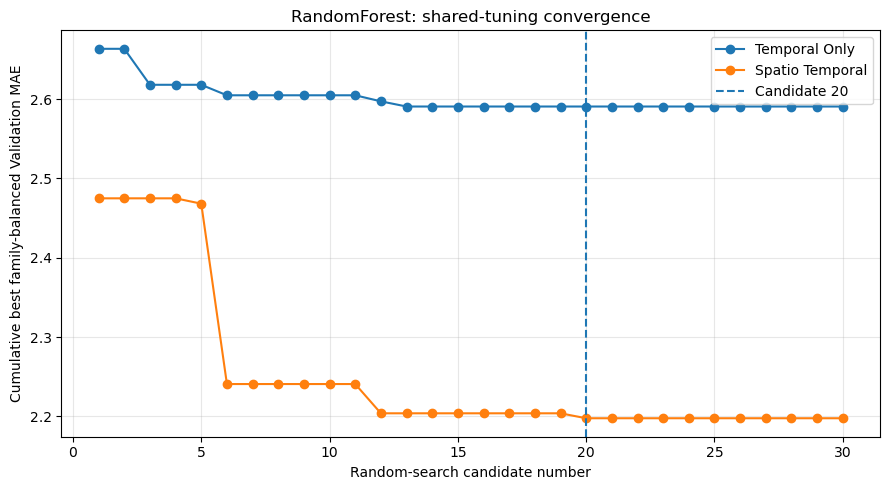

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\figures\randomforest_cumulative_best_family_balanced_mae_shared_family_balanced.png


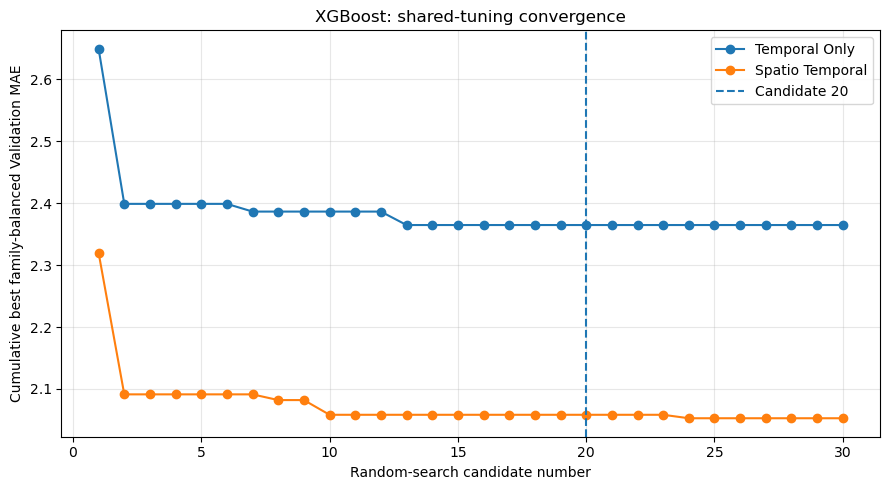

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\figures\xgboost_cumulative_best_family_balanced_mae_shared_family_balanced.png


In [38]:
cumulative_figure_paths = {}

for model_name in [
    "RandomForest",
    "XGBoost",
]:
    plt.figure(
        figsize=(9, 5)
    )

    for feature_set_name in (
        FEATURE_SETS
    ):
        subset = (
            all_tuning_results.loc[
                all_tuning_results[
                    "Model"
                ].eq(
                    model_name
                )
                & all_tuning_results[
                    "FeatureSet"
                ].eq(
                    feature_set_name
                )
            ]
            .sort_values(
                "CandidateNumber"
            )
        )

        plt.plot(
            subset[
                "CandidateNumber"
            ],
            subset[
                "CumulativeBest_FamilyBalancedMAE"
            ],
            marker="o",
            label=(
                feature_set_name
                .replace(
                    "_",
                    " ",
                )
                .title()
            ),
        )

    plt.axvline(
        20,
        linestyle="--",
        label="Candidate 20",
    )

    plt.xlabel(
        "Random-search candidate number"
    )

    plt.ylabel(
        "Cumulative best family-balanced "
        "Validation MAE"
    )

    plt.title(
        f"{model_name}: shared-tuning convergence"
    )

    plt.legend()
    plt.grid(
        alpha=0.3
    )
    plt.tight_layout()

    figure_path = (
        FIGURE_DIR
        / (
            f"{model_name.lower()}_"
            "cumulative_best_family_balanced_mae"
            f"{OUTPUT_SUFFIX}.png"
        )
    )

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    cumulative_figure_paths[
        model_name
    ] = str(
        figure_path
    )

    print(
        f"Saved: {figure_path}"
    )


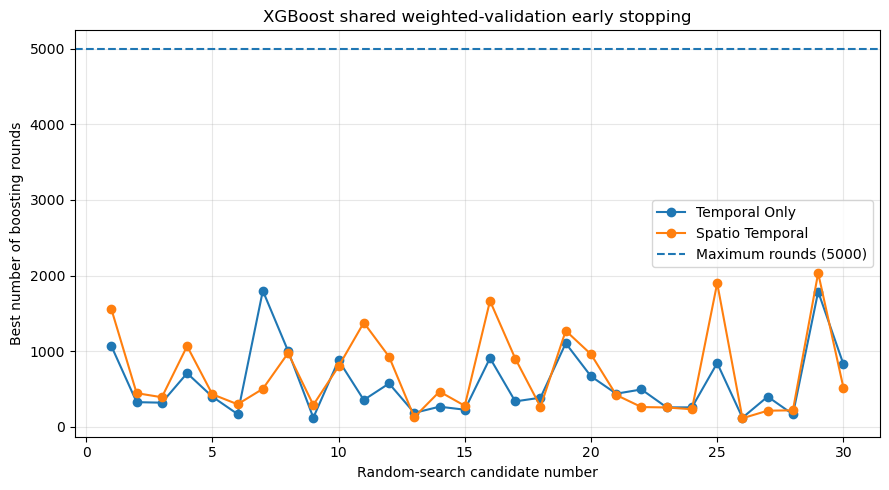

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\figures\xgboost_best_iterations_shared_family_balanced.png


In [39]:
plt.figure(
    figsize=(9, 5)
)

for feature_set_name in (
    FEATURE_SETS
):
    subset = (
        xgb_iteration_audit.loc[
            xgb_iteration_audit[
                "FeatureSet"
            ].eq(
                feature_set_name
            )
        ]
        .sort_values(
            "CandidateNumber"
        )
    )

    plt.plot(
        subset[
            "CandidateNumber"
        ],
        subset[
            "BestNEstimators"
        ],
        marker="o",
        label=(
            feature_set_name
            .replace(
                "_",
                " ",
            )
            .title()
        ),
    )

plt.axhline(
    XGB_MAX_ROUNDS,
    linestyle="--",
    label=(
        f"Maximum rounds "
        f"({XGB_MAX_ROUNDS})"
    ),
)

plt.xlabel(
    "Random-search candidate number"
)

plt.ylabel(
    "Best number of boosting rounds"
)

plt.title(
    "XGBoost shared weighted-validation "
    "early stopping"
)

plt.legend()
plt.grid(
    alpha=0.3
)
plt.tight_layout()

xgb_iteration_figure_path = (
    FIGURE_DIR
    / (
        "xgboost_best_iterations"
        f"{OUTPUT_SUFFIX}.png"
    )
)

plt.savefig(
    xgb_iteration_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved: {xgb_iteration_figure_path}"
)


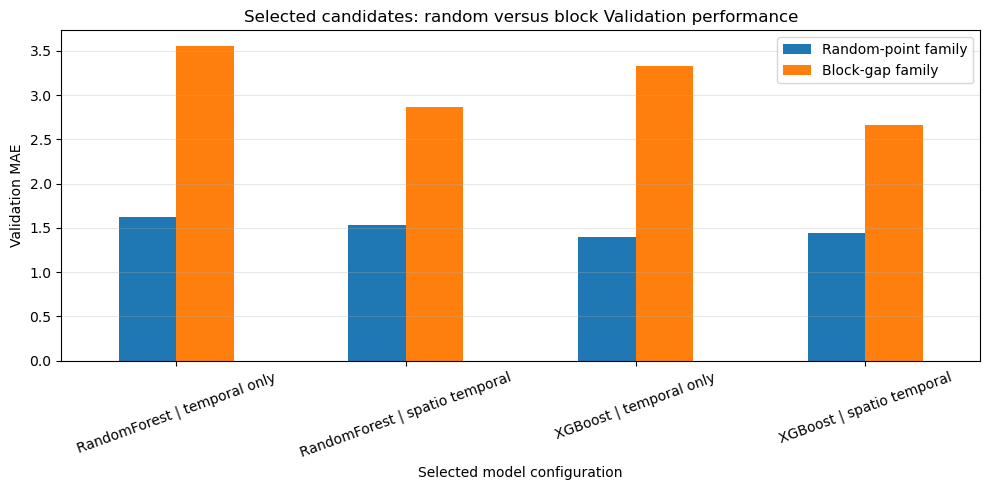

Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\figures\selected_candidate_random_vs_block_mae_shared_family_balanced.png


In [40]:
family_plot = (
    selected_family_comparison
    .assign(
        ModelConfiguration=lambda frame: (
            frame["Model"]
            + " | "
            + frame["FeatureSet"]
            .str.replace(
                "_",
                " ",
                regex=False,
            )
        )
    )
    .set_index(
        "ModelConfiguration"
    )[
        [
            "RandomMacroValidationMAE",
            "BlockMacroValidationMAE",
        ]
    ]
)

family_plot.columns = [
    "Random-point family",
    "Block-gap family",
]

axis = family_plot.plot(
    kind="bar",
    figsize=(10, 5),
)

axis.set_xlabel(
    "Selected model configuration"
)

axis.set_ylabel(
    "Validation MAE"
)

axis.set_title(
    "Selected candidates: random versus block "
    "Validation performance"
)

axis.tick_params(
    axis="x",
    rotation=20,
)

axis.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

selected_family_figure_path = (
    FIGURE_DIR
    / (
        "selected_candidate_random_vs_block_mae"
        f"{OUTPUT_SUFFIX}.png"
    )
)

plt.savefig(
    selected_family_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved: {selected_family_figure_path}"
)


## Step 13 : Shared-Tuning Outputs

Candidate tables, selected-parameter JSON files, runtime records, Validation-weight audits, weighted XGBoost checks, diagnostics, figures, environment information, and a protocol manifest are saved after both algorithms finish.


In [41]:
environment_path = (
    OUTPUT_DIR
    / (
        "computational_environment_tuning"
        f"{OUTPUT_SUFFIX}.json"
    )
)

runtime_records_path = (
    OUTPUT_DIR
    / (
        "ml_tuning_runtime_records"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

runtime_summary_path = (
    OUTPUT_DIR
    / (
        "ml_tuning_runtime_summary"
        f"{OUTPUT_SUFFIX}.csv"
    )
)

manifest_path = (
    OUTPUT_DIR
    / (
        "ml_tuning_manifest"
        f"{OUTPUT_SUFFIX}.json"
    )
)

atomic_write_json(
    environment_information,
    environment_path,
)

if not runtime_records:
    raise RuntimeError(
        "No tuning runtime records were created."
    )

runtime_df = pd.DataFrame(
    runtime_records
)

runtime_summary = (
    create_runtime_summary(
        runtime_records
    )
)

atomic_write_dataframe(
    runtime_df,
    runtime_records_path,
)

atomic_write_dataframe(
    runtime_summary,
    runtime_summary_path,
)

artifact_paths = {
    "RandomForest": {
        feature_set: str(
            RF_TUNING_OUTPUTS[
                feature_set
            ][
                "best_parameters_path"
            ]
        )
        for feature_set in FEATURE_SETS
    },
    "XGBoost": {
        feature_set: str(
            XGB_TUNING_OUTPUTS[
                feature_set
            ][
                "best_parameters_path"
            ]
        )
        for feature_set in FEATURE_SETS
    },
}

candidate_result_paths = {
    "RandomForest": {
        feature_set: str(
            RF_TUNING_OUTPUTS[
                feature_set
            ][
                "results_path"
            ]
        )
        for feature_set in FEATURE_SETS
    },
    "XGBoost": {
        feature_set: str(
            XGB_TUNING_OUTPUTS[
                feature_set
            ][
                "results_path"
            ]
        )
        for feature_set in FEATURE_SETS
    },
}

checkpoint_paths = {
    "RandomForest": {
        feature_set: str(
            RF_TUNING_OUTPUTS[
                feature_set
            ][
                "checkpoint_path"
            ]
        )
        for feature_set in FEATURE_SETS
    },
    "XGBoost": {
        feature_set: str(
            XGB_TUNING_OUTPUTS[
                feature_set
            ][
                "checkpoint_path"
            ]
        )
        for feature_set in FEATURE_SETS
    },
}

for path_group in [
    artifact_paths,
    candidate_result_paths,
    checkpoint_paths,
]:
    for model_paths in (
        path_group.values()
    ):
        for artifact_path in (
            model_paths.values()
        ):
            if not Path(
                artifact_path
            ).exists():
                raise FileNotFoundError(
                    "Missing shared-tuning artifact: "
                    f"{artifact_path}"
                )

diagnostic_artifacts = {
    "AllCandidates": str(
        all_candidates_path
    ),
    "Top5Candidates": str(
        top5_candidates_path
    ),
    "DiagnosticSummary": str(
        diagnostic_summary_path
    ),
    "BoundaryAudit": str(
        boundary_audit_path
    ),
    "XGBoostIterationAudit": str(
        xgb_iteration_audit_path
    ),
    "SelectedFamilyComparison": str(
        selected_family_comparison_path
    ),
    "ValidationWeightAudit": str(
        validation_weight_audit_path
    ),
    "ValidationFeatureMissingness": str(
        feature_missingness_path
    ),
    "XGBoostWeightedEvalSmokeTest": str(
        xgb_smoke_test_path
    ),
    "Figures": {
        "RandomForestCumulativeBestFamilyBalancedMAE": (
            cumulative_figure_paths[
                "RandomForest"
            ]
        ),
        "XGBoostCumulativeBestFamilyBalancedMAE": (
            cumulative_figure_paths[
                "XGBoost"
            ]
        ),
        "XGBoostBestIterations": str(
            xgb_iteration_figure_path
        ),
        "SelectedCandidateRandomVsBlockMAE": str(
            selected_family_figure_path
        ),
    },
}

atomic_write_json(
    {
        "Status": "complete",
        "TuningProfile": (
            TUNING_PROFILE
        ),
        "TuningCandidateCount": (
            N_TUNING_ITER
        ),
        "TuningProtocol": (
            TUNING_PROTOCOL
        ),
        "TuningProtocolVersion": (
            TUNING_PROTOCOL_VERSION
        ),
        "ReferenceScenario": (
            REFERENCE_SCENARIO
        ),
        "TuningScenarios": (
            SCENARIOS
        ),
        "ScenarioFamilies": (
            SCENARIO_FAMILIES
        ),
        "FamilyWeights": (
            FAMILY_WEIGHTS
        ),
        "NestedRandomConditions": (
            True
        ),
        "ValidationIndependenceNote": (
            "The three nested random conditions are "
            "related severity conditions and are not "
            "treated as independent Validation replicates."
        ),
        "SelectionMetric": (
            TUNING_METRIC
        ),
        "SelectionSortColumns": (
            SELECTION_SORT_COLUMNS
        ),
        "PipelineVersion": (
            ML_PIPELINE_VERSION
        ),
        "InputDataFingerprint": (
            TUNING_DATA_FINGERPRINT
        ),
        "ScenarioDataFingerprints": (
            SCENARIO_DATA_FINGERPRINTS
        ),
        "CommonTrainFeatureFingerprint": (
            COMMON_TRAIN_FEATURE_FINGERPRINT
        ),
        "RequestedNJobs": (
            TUNING_N_JOBS
        ),
        "EffectiveWorkers": (
            effective_n_jobs(
                TUNING_N_JOBS
            )
        ),
        "ExpectedXGBoostVersion": (
            EXPECTED_XGBOOST_VERSION
        ),
        "ObservedXGBoostVersion": (
            package_version(
                "xgboost"
            )
        ),
        "XGBoostWeightedEvaluationSmokeTest": (
            XGB_WEIGHTED_EVAL_SMOKE_TEST
        ),
        "BestParameterArtifacts": (
            artifact_paths
        ),
        "CandidateResultFiles": (
            candidate_result_paths
        ),
        "CheckpointFiles": (
            checkpoint_paths
        ),
        "Diagnostics": (
            diagnostic_artifacts
        ),
        "EnvironmentPath": str(
            environment_path
        ),
        "RuntimeRecordsPath": str(
            runtime_records_path
        ),
        "RuntimeSummaryPath": str(
            runtime_summary_path
        ),
    },
    manifest_path,
)

display(
    runtime_summary
)

print(
    f"Tuning profile completed: "
    f"{TUNING_PROFILE}"
)

print(
    f"Tuning protocol completed: "
    f"{TUNING_PROTOCOL_VERSION}"
)

print(
    f"Tuning manifest saved to: "
    f"{manifest_path}"
)

if TUNING_PROFILE == "pilot":
    print(
        "Shared pilot completed. Inspect all weighted-score "
        "audits, then change TUNING_PROFILE to 'full', "
        "restart the kernel, and run all cells."
    )
else:
    print(
        "Full shared family-balanced tuning completed. "
        "The final-evaluation notebook must be updated to "
        "accept only these shared artifacts before it is run."
    )


,Model,Scenario,FeatureSet,Stage,Split,RequestedNJobs,EffectiveWorkers,MedianSeconds,MeanSeconds,MinimumSeconds,MaximumSeconds,Repetitions,NumberOfRows,NumberOfFeatures,NumberOfCandidates,MillisecondsPer1000Predictions
0,RandomForest,shared_family_balanced_v1,spatio_temporal,tuning,Train_fit+Five_Validation_conditions,-1,12,"1,421.0399","1,421.0399","1,421.0399","1,421.0399",1,127512,97,30,NaN
1,RandomForest,shared_family_balanced_v1,temporal_only,tuning,Train_fit+Five_Validation_conditions,-1,12,"1,211.2257","1,211.2257","1,211.2257","1,211.2257",1,127512,86,30,NaN
2,XGBoost,shared_family_balanced_v1,spatio_temporal,tuning,Train_fit+Five_Validation_conditions,-1,12,364.3322,364.3322,364.3322,364.3322,1,127512,97,30,NaN
3,XGBoost,shared_family_balanced_v1,temporal_only,tuning,Train_fit+Five_Validation_conditions,-1,12,255.6629,255.6629,255.6629,255.6629,1,127512,86,30,NaN


Tuning profile completed: full
Tuning protocol completed: shared_family_balanced_v1
Tuning manifest saved to: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\machine_learning\ml_tuning_manifest_shared_family_balanced.json
Full shared family-balanced tuning completed. The final-evaluation notebook must be updated to accept only these shared artifacts before it is run.
